[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/19_Cybersecurity_Anomaly_Detection/VQC_AdaptiveShotAnomaly_Sudipto2026.ipynb)

# Adaptive-shot VQC for anomaly detection in Tactile Internet security: Sudipto et al. (2026) step by step

**Paper.** M. S. Sudipto, S. Ahmed, A. Khokhar and S. M. Iqbal, *Adaptive-Shot Hybrid Quantum Anomaly Detection for Tactile Internet
Security: Reliability-Aware Measurement Allocation Under Resource Constraints*, NeurIPS 2026 Workshop SaTQuML (Secure and Trustworthy
Quantum Machine Learning), arXiv:2610.05835 [cs.CR], 5 October 2026. Authors' public code (MIT): `github.com/msudipto/AdaptiveShot_HybridQAD_Framework`.
Data: Koumar, Hynek, Cejka, Siska, *CESNET-TimeSeries24*, Scientific Data 12:338 (2025), doi:10.1038/s41597-025-04603-x (CC BY 4.0, Zenodo record 13382427).

**What this notebook does.** A quantum classifier gives a *probability* of "anomalous". On a quantum computer that probability is
never read out exactly: it is *estimated* from a finite number of measurements ("shots"), so a record whose true score is close to the decision
threshold can flip to the wrong side by sampling luck alone. The paper asks whether we can spend measurements *where they matter*: start every
record at 128 shots and only add more (256, 512, 1024) while the estimate is still close to the threshold. This notebook

1. rebuilds the paper's 4,875-record benchmark **from the public CESNET-TimeSeries24 files** (the eligible-row count and all eleven split sizes come out identical to the paper),
2. trains the paper's 12-qubit hybrid quantum neural network (QNN) on the three holdouts (random, entity-group-disjoint, temporal), five checkpoints each,
3. runs the fixed-shot baselines (128/256/512/1024), the adaptive-shot policy AS-VQC-90/95/99 and the matched-budget shuffled control with **real finite-shot sampling**,
4. trains classical baselines on exactly the same inputs, and
5. prints every number the paper reports next to ours with a verdict per claim.

**How to run.** Google Colab, *CPU* runtime, Runtime -> Run all. `FAST_MODE = True` (configuration cell) is a class demo of about 10 minutes
(two checkpoints per holdout, five epochs, three finite-shot repetitions). `FAST_MODE = False` uses the paper's budgets (five checkpoints per holdout,
20 epochs, 10 repetitions, 10,000 bootstrap resamples) and takes roughly 30 to 60 minutes on a shared CPU. The data (a 163 MB archive from Zenodo) are
downloaded inside the notebook, checked against Zenodo's MD5 and streamed without being unpacked; the archive is deleted afterwards. No GPU, no quantum hardware and no token are needed.

**What you get at the end.** The paper's Table 1 and Figures 2 to 5 re-drawn from our own runs, the policy table, paired bootstrap intervals, classical baselines and a
verdict ("reproduced" / "not reached" / "exceeded" / "cannot be checked") for each claim of the paper that can be tested.

**Honest framing.** The labels are *statistical-anomaly pseudo-labels*, not verified attacks, and CESNET-TimeSeries24 is ISP telemetry, not Tactile-Internet (haptic) traffic.
The paper says so itself (its sections 1 and 6); so does this notebook.

## The paper in one page

**Problem.** A security analytics component scores aggregate flow records and a threshold turns the score into a decision. If the score comes from a
finite-shot quantum measurement, decisions near the threshold are unstable. Uniformly high shot counts waste measurements, uniformly low counts destabilise decisions.

**Decision rule (AS-VQC).** A trained QNN gives an exact (analytic) probability $p_i$; with $S$ shots we only get an estimate $\hat p_{i,S}$.
For $S \in \{128, 256, 512\}$ the notebook measures, on *validation* records, the finite-shot error $e = |\hat p_{i,S} - p_i|$ and takes its $\beta$-quantile as a margin $\delta_{S,\beta}$ (eqs. 9-10).
At test time every record starts with 128 shots and **stops at stage $S$ if $|\hat p_{i,S} - \tau^*| > \delta_{S,\beta}$** (eqs. 11-12); otherwise it receives just enough extra shots to reach the next cumulative budget 256, 512, 1024 (eq. 13).
$\tau^*$ is the threshold that maximises Youden's $J$ = TPR - FPR on the validation set (eq. 8). AS-VQC-95 ($\beta = 0.95$) is the primary policy; AS-VQC-90 and AS-VQC-99 vary the calibration level.

**Model (section 3.3).** classical embedder 12 -> 64 -> 12 (GELU) -> angles $z = \pi \tanh(\cdot)$ -> 12 qubits: `RY(z_k)` on qubit k, two layers of a trainable `Rot(phi, theta, omega)` on every qubit followed by the directed CNOT chain 0->1, ..., 10->11 -> read $\langle Z_0\rangle, \langle Z_1\rangle$ -> head 2 -> 32 -> 2 (GELU) -> softmax.
1,612 + 72 + 162 = 1,846 trainable parameters. Training: 20 epochs, Adam (lr 2e-3, weight decay 1e-4), batch 32, gradient clipping at 1.0, inverse-frequency class weights, the epoch with the best *validation* AUC is kept.
Because only qubits 0 and 1 are measured, only the encoded wires 0-2 can influence the result (backward causal cone), so the exact joint outcome distribution of the two measured qubits can be rebuilt from a **3-qubit** circuit.

**Data (section 3.1, appendix A).** CESNET-TimeSeries24, 10-minute IP-address aggregates. A uniform sample without replacement (seed 42) of 4,875 of the 6,863,540 eligible rows; 12 flow-level features
(`n_flows, n_packets, n_bytes, n_dest_asn, n_dest_ports, n_dest_ip, tcp_udp_ratio_packets, tcp_udp_ratio_bytes, dir_ratio_packets, dir_ratio_bytes, avg_duration, avg_ttl`), the time bin and the IP address (entity key) are kept.
Everything below is fitted on the **training** partition only: robust scaling $\tilde x = (x - \text{median})/\text{IQR}$ (eq. 1), a retention interval $[Q_1 - 1.5\,\text{IQR},\, Q_3 + 1.5\,\text{IQR}]$ (eq. 2),
the anomaly score $a = \lVert \tilde x \rVert_2$ (eq. 3) and the binary pseudo-label $y = [a \ge Q_{0.85}(\text{training scores})]$ (eq. 4).
Holdouts (60/20/20): **random**, **entity-group** (every IP address in exactly one partition) and **temporal** (train bins < validation bins < test bins), five training seeds each (temporal: fixed split, five model seeds).

**Claims we can test.** AS-VQC-95 uses 129.2 / 276.9 / 131.2 shots per record (random / group / temporal), saving 87.4 / 73.0 / 87.2 % of Fixed-1024, with decision disagreement w.r.t. the analytic decision of 0.771 / 0.409 / 0.635 %;
it is more stable than Fixed-128 and than a shuffled allocation with the same budget, but *less* stable than Fixed-1024; AS-VQC-99 uses fewer than 512 shots and beats Fixed-512; Table 1 AUC/AP/FPR/ECE; where the shots go (Fig. 4); and one checkpoint (group seed 46) that escalates 81.8 % of its records to 1024 shots.

### What follows the paper and what had to be chosen

The paper's appendix points to the authors' public code. Items the PDF leaves open were taken from that code or chosen by us; every such item is marked `# CHOICE:` in the code cells.

| Item | Paper | This notebook |
|---|---|---|
| Source data | CESNET-TimeSeries24, 10-minute IP aggregates, 1,000 source files, 6,863,540 eligible rows | the same files: Zenodo `ip_addresses_sample.tar.gz` (1,000 IP addresses), eligible rows are counted and compared with the paper |
| Candidate sample | two-pass uniform sample without replacement, seed 42, before scaling/filtering/labelling | the same two-pass procedure on the streamed archive; `# CHOICE:` files are ordered by sorted member name (the sorted-glob order of the authors' code) |
| Features, time bin, entity key | 12 features, `id_time`, entity key | the same; entity key = IP address file name |
| Preprocessing and labels | eqs. 1-4, training only | eqs. 1-4 coded literally, training only |
| Group holdout | "each entity key in exactly one partition" | `# CHOICE:` scikit-learn `GroupShuffleSplit` (60 %, then 50/50 of the rest), as in the authors' code; assertion: no IP address in two partitions |
| Temporal holdout | chronological bins, eq. 5 | the first 60 % / next 20 % / last 20 % of the sorted distinct time bins; assertion of eq. 5 |
| Split sizes | Table 2 | printed side by side (11 of 11 identical) |
| QNN | 12 -> 64 -> 12, 12 qubits, 2 layers, head 2 -> 32 -> 2, 1,846 parameters | identical architecture and parameter counts (asserted); weights initialised like PennyLane's `TorchLayer` (uniform on [0, 2 pi]) |
| QNN simulator | PennyLane 0.39 + PyTorch (lightning.qubit), adjoint differentiation | `# CHOICE:` a differentiable torch state-vector of the 3-wire causal cone for speed; **asserted equal (values and gradients) to the 12-qubit PennyLane QNode**, and every validation/test probability of every checkpoint is re-computed with the real 12-qubit circuit |
| Training recipe | Adam 2e-3, wd 1e-4, batch 32, 20 epochs, clip 1.0, inverse-frequency weights, best validation AUC | the same (`FAST_MODE` uses 5 epochs) |
| Threshold | Youden J on validation | the same |
| Calibration realizations | "finite-shot validation realizations" (number not given) | `# CHOICE:` 20 per stage (authors' code); 5 in `FAST_MODE` |
| Finite-shot realizations | 10 per policy and checkpoint | 10 (3 in `FAST_MODE`); sampling seeds `# CHOICE:` 73000 + holdout code + training seed (authors' code) |
| Finite-shot sampling | ideal multinomial sampling of the exact joint outcome distribution of qubits 0 and 1 | the same; checked against PennyLane's shot-based `counts` and against the binomial law of the estimate |
| Statistics | mean +/- sample SD over five checkpoints after averaging the repetitions; paired percentile bootstrap, 10,000 resamples | the same (2,000 resamples in `FAST_MODE`) |
| Classical baseline | none | RandomForest, SVC (RBF), a classical twin of the network (VQC replaced by a linear 12 -> 2 layer) and an oracle, all on the identical robust-scaled inputs |
| Hardware / noise | none (ideal sampling) | none; `IBM_TOKEN` is not used |
| Verdict tolerance | - | 0.02 on [0, 1] metrics, 2 percentage points on percentages and on shot savings (20.5 shots = 2 pp of 1024) |

In [1]:
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
_missing = [m for m in ("pennylane", "torch", "sklearn", "pandas", "requests") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:      # locally the packages are already installed; Colab already ships torch, numpy, pandas, scikit-learn
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "scikit-learn", "pandas", "requests", "matplotlib"], check=True)
    print("installed (a runtime restart may be requested by Colab; if so restart and run all again)")
else:
    print("environment already complete, nothing installed; missing:", _missing)

environment already complete, nothing installed; missing: []


### Configuration

Every tunable constant is in the next cell. `FAST_MODE` shrinks only the number of checkpoints, epochs and repetitions; the benchmark itself (4,875 records, all holdouts) is always the paper's.

In [2]:
FAST_MODE = False          # True: class demo (2 checkpoints per holdout, 5 epochs, 3 repetitions) | False: the paper's budgets
SEED = 42                      # global seed (paper: sampling seed 42)

# ---- data ----
from pathlib import Path
DATA_DIR = Path("cesnet_cache"); DATA_DIR.mkdir(exist_ok=True)   # cache for the 4,875-record candidate pool (a few hundred kB)
ARCHIVE_PATH = None            # optional: path of an ip_addresses_sample.tar.gz you already downloaded (otherwise it is fetched from Zenodo)
KEEP_ARCHIVE = False           # the 163 MB archive is deleted after use (cache rule); set True to keep it
CANDIDATE_SIZE = 4875          # paper: 4,875 records
SAMPLING_SEED = 42             # paper: uniform sample without replacement with seed 42
IQR_K, Q_SUSP, Q_HIGH = 1.5, 0.85, 0.95   # retention fence, suspicious / high-anomaly quantiles of the training scores

# ---- protocols and training ----
PROTOCOLS = ["random", "group", "temporal"]
SEEDS = [42, 43] if FAST_MODE else [42, 43, 44, 45, 46]   # paper: five checkpoints per holdout
EPOCHS = 5 if FAST_MODE else 20                           # paper: 20
BATCH_SIZE, LR, WEIGHT_DECAY = 32, 2e-3, 1e-4             # paper: Adam, lr 2e-3, wd 1e-4, batch 32, gradient clipping at 1.0

# ---- adaptive-shot evaluation ----
MEAS_REPS = 3 if FAST_MODE else 10      # finite-shot realizations per policy and checkpoint (paper: 10)
CAL_REPS = 5 if FAST_MODE else 20       # validation realizations for the margins delta_{S,beta} (CHOICE: 20, as in the authors' code)
BASE_SEED = 73000                       # CHOICE: base of the sampling seeds (authors' code)
BOOT_REPS = 2000 if FAST_MODE else 10_000   # paired bootstrap resamples (paper: 10,000)

IBM_TOKEN = ""                          # unused: the paper studies ideal finite-shot sampling only, no hardware
print(f"FAST_MODE={FAST_MODE}  seeds={SEEDS}  epochs={EPOCHS}  measurement repetitions={MEAS_REPS}")

FAST_MODE=False  seeds=[42, 43, 44, 45, 46]  epochs=20  measurement repetitions=10


Imports, library versions and seeds. Everything that is random (data sampling, splits, weight initialisation, shuffling, finite-shot sampling) is seeded;
torch is limited to one thread so that results do not depend on the machine.

In [3]:
import os, io, math, time, copy, random, hashlib, tarfile, warnings
import numpy as np, pandas as pd, requests
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import pennylane as qml
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_num_threads(1)                      # one thread: results do not depend on the number of cores
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .25})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data: CESNET-TimeSeries24 and the 4,875-record benchmark

CESNET-TimeSeries24 contains 40 weeks of traffic statistics per IP address of the Czech research network CESNET3. For each IP address and each 10-minute window it stores
12 numbers (flow, packet and byte counts, numbers of distinct destination IPs, ASNs and ports, TCP/UDP and direction ratios, average flow duration and TTL). The authors use the
`ip_addresses_sample` release: 1,000 IP addresses, one CSV file per address and aggregation level.

The next cell (a) downloads the archive and verifies its MD5, (b) **counts the eligible rows** of every 10-minute file (all 12 features present), (c) draws, with `numpy.random.default_rng(42)`,
4,875 distinct row numbers out of those eligible rows *before any scaling, filtering or labelling*, and (d) streams the archive a second time to pick exactly those rows. Nothing is unpacked to disk.
If the number of eligible rows equals the paper's 6,863,540, our candidate pool is built from the same population in the same order.

In [4]:
ZENODO_RECORD = 13382427                      # CESNET-TimeSeries24 (CC BY 4.0), Zenodo
ARCHIVE_NAME = "ip_addresses_sample.tar.gz"   # 1,000 IP addresses x 3 aggregation levels (163 MB)
ARCHIVE_MD5 = "08451dab2d1eddb29a79467b03289232"   # checksum published by Zenodo for this file
ARCHIVE_URLS = [
    f"https://zenodo.org/api/records/{ZENODO_RECORD}/files/{ARCHIVE_NAME}/content",
    f"https://zenodo.org/records/{ZENODO_RECORD}/files/{ARCHIVE_NAME}?download=1",
]
FEATURE_COLS = ["n_flows", "n_packets", "n_bytes", "n_dest_asn", "n_dest_ports", "n_dest_ip",
                "tcp_udp_ratio_packets", "tcp_udp_ratio_bytes", "dir_ratio_packets",
                "dir_ratio_bytes", "avg_duration", "avg_ttl"]
CAND_FILE = DATA_DIR / f"cesnet_candidates_{CANDIDATE_SIZE}.npz"
PAPER_ELIGIBLE_ROWS = 6_863_540               # the paper's appendix: "6,863,540 eligible rows"

def download_archive(dest):
    """Stream the archive from Zenodo, verify the MD5, retry on failure."""
    last = None
    for url in ARCHIVE_URLS:
        for attempt in range(3):
            try:
                h = hashlib.md5()
                with requests.get(url, stream=True, timeout=60) as r, open(dest, "wb") as f:
                    r.raise_for_status()
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk); h.update(chunk)
                if h.hexdigest() != ARCHIVE_MD5:
                    raise IOError(f"MD5 mismatch: {h.hexdigest()}")
                return
            except Exception as e:                      # network hiccup: try again / next URL
                last = e; print("download problem:", repr(e)[:150])
    raise RuntimeError(f"Could not download {ARCHIVE_NAME}: {last}")

def iter_10min_files(archive):
    """Stream the archive and yield (member name, eligible rows) for every 10-minute IP file.
    Eligible = all 12 features present and numeric (the authors' definition)."""
    with tarfile.open(archive, "r|gz") as tf:
        for m in tf:
            if m.isfile() and "/agg_10_minutes/" in m.name and m.name.endswith(".csv"):
                raw = tf.extractfile(m).read()
                df = pd.read_csv(io.BytesIO(raw), usecols=["id_time"] + FEATURE_COLS)
                df[FEATURE_COLS] = df[FEATURE_COLS].apply(pd.to_numeric, errors="coerce")
                yield m.name, df[~df[FEATURE_COLS].isna().any(axis=1)]

if CAND_FILE.exists():
    print("loaded cached candidate pool:", CAND_FILE)
else:
    archive = Path(ARCHIVE_PATH) if ARCHIVE_PATH else DATA_DIR / ARCHIVE_NAME
    if not archive.exists():
        t0 = time.time(); download_archive(archive)
        print(f"downloaded {archive.stat().st_size/1e6:.1f} MB in {time.time()-t0:.0f} s, MD5 verified")
    # Pass 1: count the eligible rows of every file
    t0 = time.time()
    counts = {name: len(df) for name, df in iter_10min_files(archive)}
    files = sorted(counts)            # CHOICE: sorted member path = the sorted glob order of the authors' code
    sizes = np.array([counts[f] for f in files])
    offsets = dict(zip(files, np.concatenate([[0], np.cumsum(sizes)[:-1]])))
    total = int(sizes.sum())
    print(f"pass 1: {len(files)} files, {total:,} eligible rows ({time.time()-t0:.0f} s)")
    # Uniform sample WITHOUT replacement, before any scaling / filtering / labelling (seed 42)
    selected = np.sort(np.random.default_rng(SAMPLING_SEED).choice(total, size=CANDIDATE_SIZE, replace=False))
    # Pass 2: pick the selected rows (the tar is streamed in archive order, rows re-ordered by sorted file)
    parts = {}
    for name, df in iter_10min_files(archive):
        lo = np.searchsorted(selected, offsets[name]); hi = np.searchsorted(selected, offsets[name] + counts[name])
        if hi > lo:
            sub = df.iloc[selected[lo:hi] - offsets[name]]
            parts[name] = (sub[FEATURE_COLS].to_numpy(np.float64), sub["id_time"].to_numpy(np.int64),
                           np.full(len(sub), "ip_addresses_sample:" + Path(name).stem))
    keys = [f for f in files if f in parts]
    X_raw = np.vstack([parts[k][0] for k in keys]); id_time = np.concatenate([parts[k][1] for k in keys])
    group_key = np.concatenate([parts[k][2] for k in keys])
    assert len(X_raw) == CANDIDATE_SIZE
    np.savez(CAND_FILE, X_raw=X_raw, id_time=id_time, group_key=group_key,
             feature_cols=np.array(FEATURE_COLS), eligible_rows=total, n_files=len(files))
    print(f"pass 2 done ({time.time()-t0:.0f} s)")
    if not ARCHIVE_PATH and not KEEP_ARCHIVE and archive.stat().st_size > 50e6:
        archive.unlink(); print("archive deleted again (cache rule: no cached file above 50 MB)")

cand = np.load(CAND_FILE, allow_pickle=True)
X_raw, id_time, group_key = cand["X_raw"], cand["id_time"], cand["group_key"].astype(str)
ELIGIBLE_ROWS, N_SOURCE_FILES = int(cand["eligible_rows"]), int(cand["n_files"])
print(f"candidate pool: {X_raw.shape[0]} records x {X_raw.shape[1]} features from {N_SOURCE_FILES} IP files; "
      f"{len(np.unique(group_key))} distinct IP addresses; {len(np.unique(id_time))} distinct 10-minute bins")
print(f"eligible rows in the source view: {ELIGIBLE_ROWS:,}  (paper: {PAPER_ELIGIBLE_ROWS:,}) ->",
      "MATCH" if ELIGIBLE_ROWS == PAPER_ELIGIBLE_ROWS else "DIFFERENT")

downloaded 170.9 MB in 63 s, MD5 verified


pass 1: 1000 files, 6,863,540 eligible rows (26 s)


pass 2 done (58 s)
archive deleted again (cache rule: no cached file above 50 MB)
candidate pool: 4875 records x 12 features from 1000 IP files; 689 distinct IP addresses; 4596 distinct 10-minute bins
eligible rows in the source view: 6,863,540  (paper: 6,863,540) -> MATCH


## 2. Splits, training-only preprocessing and pseudo-labels

For each holdout the 4,875 records are split 60/20/20 **before** anything is fitted. The training partition then determines (i) the median and IQR for robust scaling, (ii) the retention interval that removes extreme
records from all three partitions, (iii) the anomaly score $a = \lVert\tilde x\rVert_2$ and (iv) its 0.85 and 0.95 quantiles. A record is a (pseudo-)anomaly if its score reaches the 0.85-quantile of the *training* scores
(binary task); the 0.95 quantile only defines a third, "high-anomaly" level that we use for plotting. Validation and test records are transformed with the frozen training statistics, so no information flows from them into the pipeline.
The table compares our post-filter sizes with the paper's appendix Table 2.

In [5]:
def split_random(n, seed, train_f=0.6, val_f=0.2):
    idx = np.random.default_rng(seed).permutation(n)          # seeded record permutation
    ntr, nva = int(round(train_f * n)), int(round(val_f * n))
    return idx[:ntr], idx[ntr:ntr + nva], idx[ntr + nva:]

def split_group(groups, seed, train_f=0.6, val_f=0.2, test_f=0.2):
    idx = np.arange(len(groups))                              # each IP address ends up in exactly one partition
    tr, rest = next(GroupShuffleSplit(n_splits=1, train_size=train_f, random_state=seed).split(idx, groups=groups))
    va_rel, te_rel = next(GroupShuffleSplit(n_splits=1, train_size=val_f / (val_f + test_f),
                                            random_state=seed + 10000).split(rest, groups=groups[rest]))
    return tr, rest[va_rel], rest[te_rel]

def split_temporal(times, train_f=0.6, val_f=0.2):
    uniq = np.unique(times)                                   # ordered 10-minute bins, cut chronologically
    i1 = max(1, min(len(uniq) - 2, int(round(train_f * len(uniq)))))
    i2 = max(i1 + 1, min(len(uniq) - 1, int(round((train_f + val_f) * len(uniq)))))
    return (np.where(np.isin(times, uniq[:i1]))[0], np.where(np.isin(times, uniq[i1:i2]))[0],
            np.where(np.isin(times, uniq[i2:]))[0])

def fit_apply_preprocess(X, tr_idx, va_idx, te_idx, iqr_k=IQR_K, q_susp=Q_SUSP, q_high=Q_HIGH):
    """Paper section 3.1: robust scaling (eq. 1), training-derived retention interval (eq. 2),
    anomaly score = L2 norm (eq. 3), pseudo-label = score >= training 0.85-quantile (eq. 4).
    EVERY statistic is computed on the training partition only and frozen for validation and test."""
    Xtr_raw = X[tr_idx]
    med = np.median(Xtr_raw, axis=0)
    iqr = np.quantile(Xtr_raw, 0.75, axis=0) - np.quantile(Xtr_raw, 0.25, axis=0)
    iqr = np.where(iqr == 0, 1.0, iqr)                        # zero IQR replaced by one
    scale = lambda A: (A - med) / iqr
    Xtr, Xva, Xte = scale(Xtr_raw), scale(X[va_idx]), scale(X[te_idx])
    q1, q3 = np.quantile(Xtr, 0.25, axis=0), np.quantile(Xtr, 0.75, axis=0)
    fiqr = np.where(q3 - q1 == 0, 1.0, q3 - q1)
    lo, hi = q1 - iqr_k * fiqr, q3 + iqr_k * fiqr             # frozen retention interval
    keep = lambda A: np.all((A >= lo) & (A <= hi), axis=1)
    mtr, mva, mte = keep(Xtr), keep(Xva), keep(Xte)
    Xtr, Xva, Xte = Xtr[mtr], Xva[mva], Xte[mte]
    tr_k, va_k, te_k = tr_idx[mtr], va_idx[mva], te_idx[mte]
    s_tr = np.linalg.norm(Xtr, axis=1)
    t_susp, t_high = float(np.quantile(s_tr, q_susp)), float(np.quantile(s_tr, q_high))
    def labels(A):
        s = np.linalg.norm(A, axis=1)
        y3 = np.zeros(len(A), np.int64); y3[(s >= t_susp) & (s < t_high)] = 1; y3[s >= t_high] = 2
        return (s >= t_susp).astype(np.int64), y3, s
    out = {}
    for name, A, ix in (("train", Xtr, tr_k), ("val", Xva, va_k), ("test", Xte, te_k)):
        y, y3, s = labels(A)
        assert len(y) > 0 and np.unique(y).size == 2, f"{name} partition empty or single-class"
        out[name] = dict(X=A.astype(np.float32), y=y, y3=y3, score=s, idx=ix)
    out["params"] = dict(median=med, iqr=iqr, lo=lo, hi=hi, t_susp=t_susp, t_high=t_high)
    return out

def make_split(protocol, seed):
    if protocol == "random":
        tr, va, te = split_random(len(X_raw), seed)
    elif protocol == "group":
        tr, va, te = split_group(group_key, seed)
    else:
        tr, va, te = split_temporal(id_time)
    sp = fit_apply_preprocess(X_raw, tr, va, te)
    sp["protocol"], sp["seed"] = protocol, seed
    ig = {k: set(group_key[sp[k]["idx"]]) for k in ("train", "val", "test")}
    it = {k: id_time[sp[k]["idx"]] for k in ("train", "val", "test")}
    if protocol == "group":                                   # leakage invariants of the paper
        assert not (ig["train"] & ig["val"] or ig["train"] & ig["test"] or ig["val"] & ig["test"]), "IP leakage"
    if protocol == "temporal":
        assert it["train"].max() < it["val"].min() <= it["val"].max() < it["test"].min(), "temporal order (eq. 5)"
    return sp

SPLITS = {}
for protocol in PROTOCOLS:
    for seed in (SEEDS if protocol != "temporal" else [None]):
        SPLITS[(protocol, seed)] = make_split(protocol, seed if seed is not None else 0)

# Paper appendix Table 2: post-filter sizes (train, validation, test) of the saved Paper-3 splits
PAPER_TABLE2 = {("random", 42): (1794, 602, 615), ("random", 43): (1773, 602, 591), ("random", 44): (1783, 591, 624),
                ("random", 45): (1746, 592, 576), ("random", 46): (1801, 595, 583),
                ("group", 42): (1688, 621, 653), ("group", 43): (1872, 592, 522), ("group", 44): (1818, 590, 506),
                ("group", 45): (1828, 636, 592), ("group", 46): (1762, 469, 669), ("temporal", None): (1755, 561, 605)}
rows = []
for (protocol, seed), sp in SPLITS.items():
    mine = tuple(len(sp[k]["y"]) for k in ("train", "val", "test"))
    rows.append(dict(protocol=protocol, seed=seed, train=mine[0], val=mine[1], test=mine[2],
                     paper=PAPER_TABLE2[(protocol, seed)], identical=mine == PAPER_TABLE2[(protocol, seed)],
                     pos_rate_test=round(float(sp["test"]["y"].mean()), 3)))
split_table = pd.DataFrame(rows)
display(split_table)
print(f"{int(split_table.identical.sum())} of {len(split_table)} split sizes are identical to the paper's Table 2")

,protocol,seed,train,val,test,paper,identical,pos_rate_test
0,random,42.0,1794,602,615,"(1794, 602, 615)",True,0.133
1,random,43.0,1773,602,591,"(1773, 602, 591)",True,0.171
2,random,44.0,1783,591,624,"(1783, 591, 624)",True,0.120
3,random,45.0,1746,592,576,"(1746, 592, 576)",True,0.149
4,random,46.0,1801,595,583,"(1801, 595, 583)",True,0.101
5,group,42.0,1688,621,653,"(1688, 621, 653)",True,0.130
6,group,43.0,1872,592,522,"(1872, 592, 522)",True,0.132
7,group,44.0,1818,590,506,"(1818, 590, 506)",True,0.164
8,group,45.0,1828,636,592,"(1828, 636, 592)",True,0.110
9,group,46.0,1762,469,669,"(1762, 469, 669)",True,0.124


11 of 11 split sizes are identical to the paper's Table 2


## Dataset Exploration and Visualisation

There is **no ground-truth attack label** in CESNET-TimeSeries24. The labels used here are the paper's training-derived statistical-anomaly pseudo-labels, so "ground truth" below means "the label the paper defines". We keep the
three-level version (normal / suspicious / high-anomaly) for colouring; the binary task merges the last two. The first cell prints the shape, the feature names, the label counts of every split and draws the class distribution
and the score histogram; the second cell shows real flows in two PCA coordinates (PCA fitted on the training split only) coloured by label, in raw coordinates and rescaled to angles in $[0,\pi]$ as a quantum angle encoding would use them.
(The model itself uses *learned* angles from its embedder; they are plotted in section 8.)

Source: CESNET-TimeSeries24, 10-minute IP-address aggregates, ip_addresses_sample (CC BY 4.0)
candidate pool shape      : (4875, 12)   (records x features)
feature names (12)        : ['n_flows', 'n_packets', 'n_bytes', 'n_dest_asn', 'n_dest_ports', 'n_dest_ip', 'tcp_udp_ratio_packets', 'tcp_udp_ratio_bytes', 'dir_ratio_packets', 'dir_ratio_bytes', 'avg_duration', 'avg_ttl']
extra columns kept        : id_time (10-minute bin id, 4596 distinct), group key = IP address (689 distinct)
original labels           : none.  CESNET-TimeSeries24 has no attack labels; the paper builds TRAINING-DERIVED
                            statistical-anomaly PSEUDO-labels from the robust-scaled L2 norm (eqs. 3-4).

raw feature summary of the 4,875 candidate records:


,min,25%,50%,75%,max
n_flows,1.0,4.000,7.00,17.000,2.854225e+06
n_packets,1.0,9.000,34.00,163.000,2.906633e+06
n_bytes,36.0,448.000,4087.00,36225.000,1.602386e+09
n_dest_asn,0.0,3.000,4.00,7.000,1.938000e+03
n_dest_ports,1.0,3.000,4.00,6.000,3.146300e+04
n_dest_ip,1.0,3.000,6.00,12.000,3.325400e+04
tcp_udp_ratio_packets,0.0,0.500,0.96,1.000,1.000000e+00
tcp_udp_ratio_bytes,0.0,0.400,0.99,1.000,1.000000e+00
dir_ratio_packets,0.0,0.330,0.46,0.580,1.000000e+00
dir_ratio_bytes,0.0,0.230,0.43,0.620,1.000000e+00



label counts after the training-only filter and labelling (3 levels used for plots, binary = suspicious or high):


,protocol,seed,partition,n,normal,suspicious,high_anomaly,anomaly_rate
0,random,42.0,train,1794,1525,179,90,0.150
1,random,42.0,val,602,517,64,21,0.141
2,random,42.0,test,615,533,63,19,0.133
3,group,42.0,train,1688,1434,169,85,0.150
4,group,42.0,val,621,556,50,15,0.105
5,group,42.0,test,653,568,56,29,0.130
6,temporal,NaN,train,1755,1491,176,88,0.150
7,temporal,NaN,val,561,480,51,30,0.144
8,temporal,NaN,test,605,505,69,31,0.165


thresholds fitted on the training partition of random/seed 42: suspicious >= 2.662, high-anomaly >= 3.170 (L2 norm of robust-scaled features)


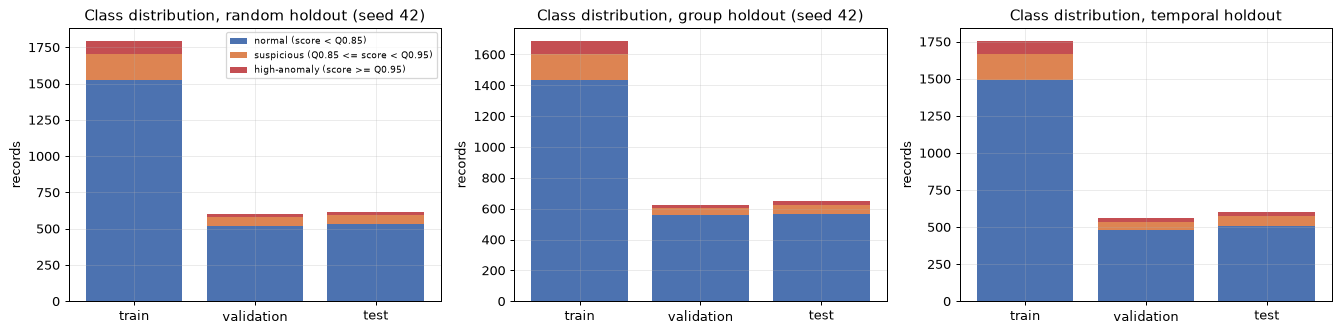

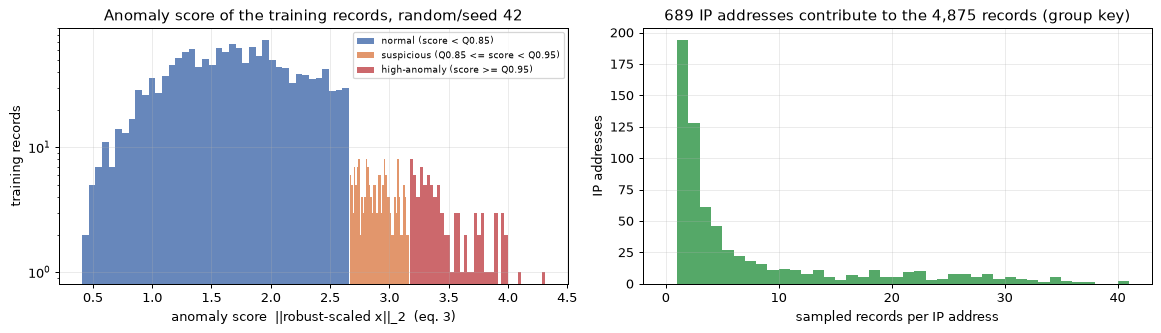

In [6]:
LABEL_NAMES = {0: "normal (score < Q0.85)", 1: "suspicious (Q0.85 <= score < Q0.95)", 2: "high-anomaly (score >= Q0.95)"}
LABEL_COLORS = {0: "#4c72b0", 1: "#dd8452", 2: "#c44e52"}
sp42 = SPLITS[("random", 42)]
print("Source: CESNET-TimeSeries24, 10-minute IP-address aggregates, ip_addresses_sample (CC BY 4.0)")
print(f"candidate pool shape      : {X_raw.shape}   (records x features)")
print(f"feature names ({len(FEATURE_COLS)})        : {FEATURE_COLS}")
print(f"extra columns kept        : id_time (10-minute bin id, {len(np.unique(id_time))} distinct), group key = IP address ({len(np.unique(group_key))} distinct)")
print("original labels           : none.  CESNET-TimeSeries24 has no attack labels; the paper builds TRAINING-DERIVED")
print("                            statistical-anomaly PSEUDO-labels from the robust-scaled L2 norm (eqs. 3-4).")
print("\nraw feature summary of the 4,875 candidate records:")
display(pd.DataFrame(X_raw, columns=FEATURE_COLS).describe().T[["min", "25%", "50%", "75%", "max"]].round(3))
print("\nlabel counts after the training-only filter and labelling (3 levels used for plots, binary = suspicious or high):")
rows = []
for (pr, sd), sp in SPLITS.items():
    for part in ("train", "val", "test"):
        c = np.bincount(sp[part]["y3"], minlength=3)
        rows.append(dict(protocol=pr, seed=sd, partition=part, n=int(c.sum()), normal=int(c[0]), suspicious=int(c[1]),
                         high_anomaly=int(c[2]), anomaly_rate=round(float((c[1] + c[2]) / c.sum()), 3)))
label_table = pd.DataFrame(rows)
display(label_table[label_table.seed.isin([42, np.nan]) | label_table.seed.isna()].reset_index(drop=True))
print("thresholds fitted on the training partition of random/seed 42: suspicious >= %.3f, high-anomaly >= %.3f (L2 norm of robust-scaled features)"
      % (sp42["params"]["t_susp"], sp42["params"]["t_high"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for ax, key in zip(axes, [("random", 42), ("group", 42), ("temporal", None)]):
    sp = SPLITS[key]; bottoms = np.zeros(3)
    for lab in (0, 1, 2):
        vals = np.array([np.sum(sp[part]["y3"] == lab) for part in ("train", "val", "test")])
        ax.bar(["train", "validation", "test"], vals, bottom=bottoms, color=LABEL_COLORS[lab], label=LABEL_NAMES[lab]); bottoms += vals
    ax.set_title(f"Class distribution, {key[0]} holdout" + (f" (seed {key[1]})" if key[1] else "")); ax.set_ylabel("records")
axes[0].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sc = sp42["train"]["score"]
for lab in (0, 1, 2):
    axes[0].hist(sc[sp42["train"]["y3"] == lab], bins=40, color=LABEL_COLORS[lab], alpha=.85, label=LABEL_NAMES[lab])
axes[0].set_yscale("log"); axes[0].set_xlabel("anomaly score  ||robust-scaled x||_2  (eq. 3)"); axes[0].set_ylabel("training records")
axes[0].set_title("Anomaly score of the training records, random/seed 42"); axes[0].legend(fontsize=7)
per_ip = pd.Series(group_key).value_counts()
axes[1].hist(per_ip.values, bins=np.arange(0, per_ip.max() + 2), color="#55a868"); axes[1].set_xlabel("sampled records per IP address")
axes[1].set_ylabel("IP addresses"); axes[1].set_title(f"{len(per_ip)} IP addresses contribute to the 4,875 records (group key)")
plt.tight_layout(); plt.show()

random holdout, seed 42: PCA explained variance of PC1, PC2 = [0.276 0.245]
temporal holdout: PCA explained variance of PC1, PC2 = [0.266 0.24 ]


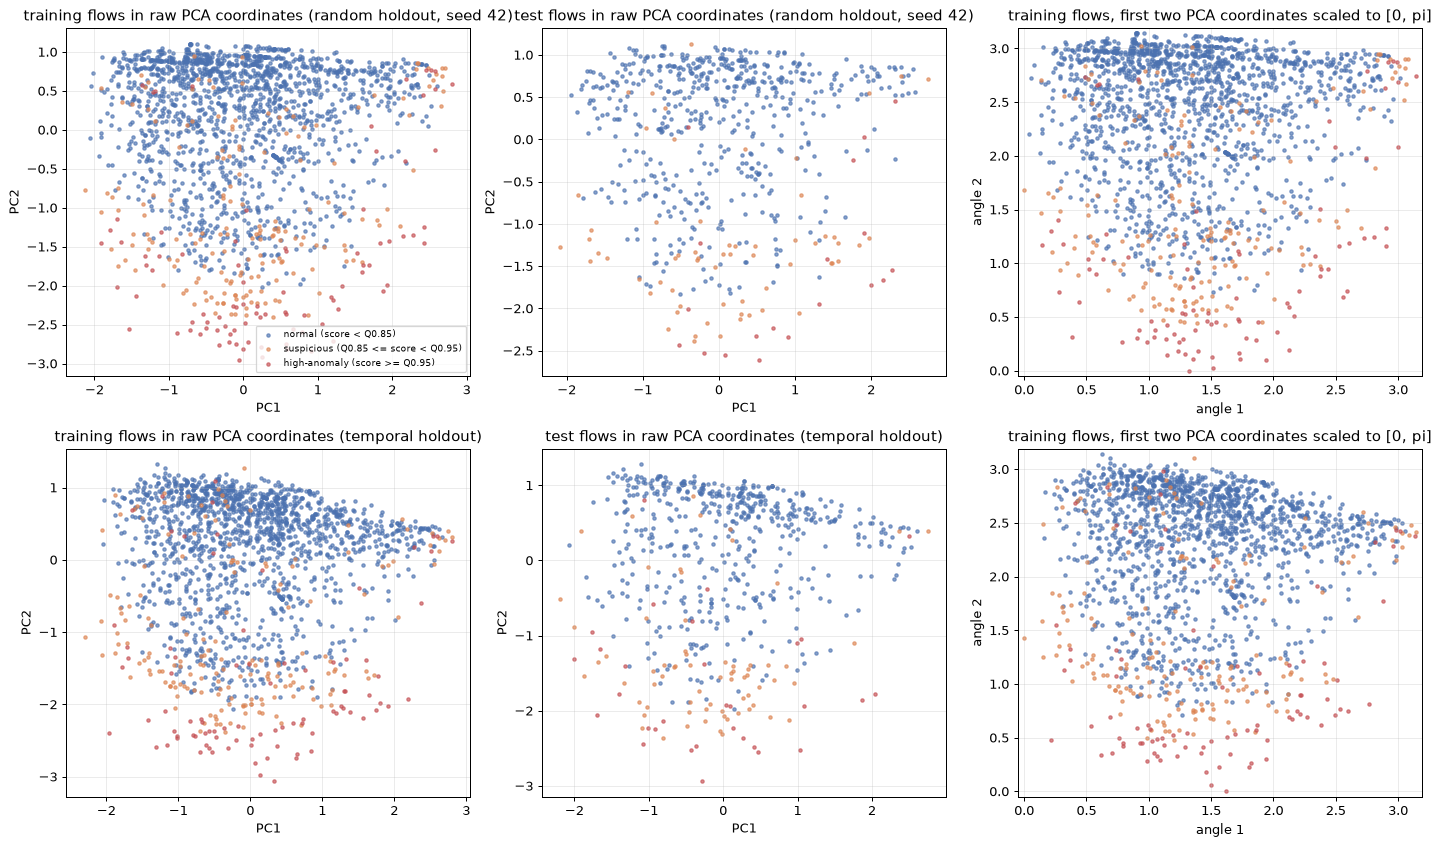

Reading the picture: the label is a monotone function of the distance from the training median in robust-scaled space, so the classes
form nested shells (high-anomaly at the outside).  This is a statistical-anomaly label, not a verified attack label (paper section 6).


In [7]:
# 2-D scatter of REAL flows coloured by their ground-truth (pseudo-)label.  PCA is fitted on the training split only.
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for r, key in enumerate([("random", 42), ("temporal", None)]):
    sp = SPLITS[key]
    pca = PCA(n_components=2, random_state=SEED).fit(sp["train"]["X"])
    Ztr, Zte = pca.transform(sp["train"]["X"]), pca.transform(sp["test"]["X"])
    mm = MinMaxScaler((0, np.pi)).fit(Ztr)                                  # scaling fitted on training coordinates only
    Atr, Ate = mm.transform(Ztr), np.clip(mm.transform(Zte), 0, np.pi)      # test angles clipped to [0, pi]
    title = f"{key[0]} holdout" + (f", seed {key[1]}" if key[1] else "")
    for ax, (A, y, nm) in zip(axes[r][:2], [(Ztr, sp["train"]["y3"], "training"), (Zte, sp["test"]["y3"], "test")]):
        for lab in (0, 1, 2):
            ax.scatter(A[y == lab, 0], A[y == lab, 1], s=7, alpha=.65, color=LABEL_COLORS[lab], label=LABEL_NAMES[lab])
        ax.set_title(f"{nm} flows in raw PCA coordinates ({title})"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    for lab in (0, 1, 2):
        axes[r][2].scatter(Atr[sp["train"]["y3"] == lab, 0], Atr[sp["train"]["y3"] == lab, 1], s=7, alpha=.65, color=LABEL_COLORS[lab])
    axes[r][2].set_title(f"training flows, first two PCA coordinates scaled to [0, pi]"); axes[r][2].set_xlabel("angle 1"); axes[r][2].set_ylabel("angle 2")
    axes[r][2].set_xlim(-.05, np.pi + .05); axes[r][2].set_ylim(-.05, np.pi + .05)
    print(f"{title}: PCA explained variance of PC1, PC2 = {pca.explained_variance_ratio_.round(3)}")
axes[0][0].legend(fontsize=7, loc="best")
plt.tight_layout(); plt.show()
print("Reading the picture: the label is a monotone function of the distance from the training median in robust-scaled space, so the classes\n"
      "form nested shells (high-anomaly at the outside).  This is a statistical-anomaly label, not a verified attack label (paper section 6).")

## 3. The hybrid QNN and its exact simulators

The model is a classical embedder, a 12-qubit variational circuit and a classical head. Three things are defined in the next cell:

* `qnode12`: **the paper's circuit as a PennyLane QNode** (12 qubits, `RY` encoding, two layers of `Rot` + CNOT chain, readout of $\langle Z_0\rangle$ and $\langle Z_1\rangle$). This is the reference.
* `qnode3`: the same circuit reduced to wires 0-2. Why is that exact? Measuring $Z_0$ and $Z_1$ at the end, one can propagate the observables backwards through the gates (Heisenberg picture). The final CNOT chain turns $Z_0, Z_1$ into $Z_0$ and $Z_0Z_1$; the second `Rot` layer keeps them on wires 0 and 1; the first CNOT chain spreads at most to wire 2; every gate that acts only on wires 3-11 drops out. This returns the joint distribution $(p_{00}, p_{01}, p_{10}, p_{11})$ of the two measured qubits.
* `joint_probs_torch` and `HybridQNN`: the reduced circuit written as differentiable torch matrices (an 8-dimensional state vector), which makes training roughly a thousand times faster than the 12-qubit circuit while giving **the same values and the same gradients**. The assertions at the end of the cell prove it numerically.

`# CHOICE:` The paper trained with PennyLane's adjoint differentiation on the 12-qubit circuit; the torch simulator is our speed-up, not a change of the model.

In [8]:
N_Q, N_LAYERS = 12, 2                      # 12 qubits, two variational layers (paper section 3.3)

# ---------- (a) the reference circuit: the paper's full 12-qubit QNode in PennyLane ----------
dev12 = qml.device("default.qubit", wires=N_Q)

@qml.qnode(dev12, interface="torch", diff_method="backprop")
def qnode12(angles, weights):
    """angles: (B, 12) encoding angles, weights: (2, 12, 3).  Returns <Z0>, <Z1> (paper eq. 7)."""
    for i in range(N_Q):
        qml.RY(angles[..., i], wires=i)                          # angle encoding, one feature per qubit
    for l in range(N_LAYERS):
        for i in range(N_Q):
            qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=i)   # trainable rotation
        for i in range(N_Q - 1):
            qml.CNOT(wires=[i, i + 1])                           # directed CNOT chain 0->1, ..., 10->11
    return [qml.expval(qml.PauliZ(0)), qml.expval(qml.PauliZ(1))]

# ---------- (b) the reduced (backward-causal-cone) circuit on wires 0-2, in PennyLane ----------
dev3 = qml.device("default.qubit", wires=3)

@qml.qnode(dev3, interface="torch", diff_method="backprop")
def qnode3(angles, weights):
    """Exact reduction of qnode12 for the readout of qubits 0 and 1 (paper section 3.3): only the
    encoded wires 0-2 lie in the backward causal cone of Z0 and Z1.  Returns the joint distribution
    of the measured qubits (0, 1) = (p00, p01, p10, p11)."""
    for i in range(3):
        qml.RY(angles[..., i], wires=i)
    for l in range(N_LAYERS):
        for i in range(3):
            qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=i)
        qml.CNOT(wires=[0, 1]); qml.CNOT(wires=[1, 2])
    return qml.probs(wires=[0, 1])

# ---------- (c) the same reduced circuit as a differentiable torch state-vector (used for training) ----------
def _rot_matrix(phi, theta, omega):
    """PennyLane's Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) as a 2x2 complex matrix."""
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    e = lambda x: torch.exp(1j * x)
    return torch.stack([torch.stack([e(-(phi + omega) / 2) * c, -e((phi - omega) / 2) * s]),
                        torch.stack([e(-(phi - omega) / 2) * s, e((phi + omega) / 2) * c])])

_CNOT01 = torch.zeros(8, 8, dtype=torch.complex128)             # basis |q0 q1 q2>, q0 = most significant bit
_CNOT12 = torch.zeros(8, 8, dtype=torch.complex128)
for _b in range(8):
    _q0, _q1, _q2 = (_b >> 2) & 1, (_b >> 1) & 1, _b & 1
    _CNOT01[(_q0 << 2) | ((_q1 ^ _q0) << 1) | _q2, _b] = 1
    _CNOT12[(_q0 << 2) | (_q1 << 1) | (_q2 ^ _q1), _b] = 1

def joint_probs_torch(angles, weights):
    """Exact (p00, p01, p10, p11) of qubits (0, 1) from 3 encoding angles per record.  angles: (B, >=3)."""
    a = angles[:, :3].double()
    prod = [torch.stack([torch.cos(a[:, i] / 2), torch.sin(a[:, i] / 2)], dim=1) for i in range(3)]   # RY|0>
    psi = torch.einsum("bi,bj,bk->bijk", *prod).reshape(-1, 8).to(torch.complex128)
    w = weights.double()
    for l in range(N_LAYERS):
        u = torch.kron(torch.kron(_rot_matrix(*w[l, 0]), _rot_matrix(*w[l, 1])), _rot_matrix(*w[l, 2]))
        psi = psi @ (_CNOT12 @ _CNOT01 @ u).T                   # Rot layer, then CNOT(0,1), CNOT(1,2)
    p = (psi.real ** 2 + psi.imag ** 2).reshape(-1, 4, 2).sum(-1)
    return p

def z_expectations(joint):
    """<Z0>, <Z1> from the joint distribution of qubits 0 and 1 (also used for finite-shot estimates)."""
    p00, p01, p10, p11 = joint.unbind(-1)
    return torch.stack([p00 + p01 - p10 - p11, p00 - p01 + p10 - p11], dim=-1)

class HybridQNN(nn.Module):
    """12 -> 64 -> 12 GELU embedder, pi*tanh angle bounding, 12-qubit VQC (quantum part: weights, evaluated
    exactly on its 3-wire causal cone), 2 -> 32 -> 2 GELU head.  1,846 trainable parameters."""
    def __init__(self, n_features=12, classical_twin=False):
        super().__init__()
        self.embedder = nn.Sequential(nn.Linear(n_features, 64), nn.GELU(), nn.Linear(64, N_Q))
        if classical_twin:                                       # classical analogue: 12 -> 2 linear map instead of the VQC
            self.weights = None; self.twin = nn.Linear(N_Q, 2)
        else:                                                    # same initialisation as PennyLane's TorchLayer
            self.weights = nn.Parameter(torch.nn.init.uniform_(torch.empty(N_LAYERS, N_Q, 3), b=2 * math.pi))
            self.twin = None
        self.head = nn.Sequential(nn.Linear(2, 32), nn.GELU(), nn.Linear(32, 2))

    def angles(self, x):
        return torch.tanh(self.embedder(x)) * math.pi            # eq. 6

    def quantum_out(self, angles):
        if self.twin is not None:
            return self.twin(angles)
        return z_expectations(joint_probs_torch(angles, self.weights)).float()

    def forward(self, x):
        return F.log_softmax(self.head(self.quantum_out(self.angles(x))), dim=1)

    def joint(self, x):
        with torch.no_grad():
            return joint_probs_torch(self.angles(x), self.weights)

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_m = HybridQNN()
PARAMS = dict(embedder=count_params(_m.embedder), vqc=_m.weights.numel(), head=count_params(_m.head), total=count_params(_m))
print("trainable parameters:", PARAMS, "(paper: embedder 1,612, VQC 72, head 162, total 1,846)")
assert PARAMS == dict(embedder=1612, vqc=72, head=162, total=1846)

# ---------- equivalence checks: torch simulator == 3-wire QNode == full 12-qubit QNode ----------
torch.manual_seed(SEED)
_ang = (torch.rand(64, N_Q, dtype=torch.float64) * 2 - 1) * math.pi
_w = torch.rand(N_LAYERS, N_Q, 3, dtype=torch.float64) * 2 * math.pi
_z12 = torch.stack(qnode12(_ang, _w), dim=-1)                          # full 12-qubit circuit
_j3 = qnode3(_ang[:, :3], _w[:, :3, :])                                # 3-wire PennyLane circuit
_jt = joint_probs_torch(_ang, _w)                                      # torch simulator
print("max |torch - 3-wire QNode|  joint probs :", float((_jt - _j3).abs().max()))
print("max |torch - 12-qubit QNode| <Z0>,<Z1>  :", float((z_expectations(_jt) - _z12).abs().max()))
assert torch.allclose(_jt, _j3, atol=1e-12) and torch.allclose(z_expectations(_jt), _z12, atol=1e-12)

# gradients must agree as well, because the training uses the torch simulator
_a1 = _ang[:8].clone().requires_grad_(True); _w1 = _w.clone().requires_grad_(True)
_g12 = torch.autograd.grad(torch.stack(qnode12(_a1, _w1), -1).pow(2).sum(), [_a1, _w1])
_a2 = _ang[:8].clone().requires_grad_(True); _w2 = _w.clone().requires_grad_(True)
_g3 = torch.autograd.grad(z_expectations(joint_probs_torch(_a2, _w2)).pow(2).sum(), [_a2, _w2])
print("max gradient difference (angles, weights):", float((_g12[0] - _g3[0]).abs().max()), float((_g12[1] - _g3[1]).abs().max()))
assert torch.allclose(_g12[0], _g3[0], atol=1e-10) and torch.allclose(_g12[1], _g3[1], atol=1e-10)
print("EQUIVALENCE OK: the torch simulator used for training is the paper's 12-qubit circuit (values and gradients).")

trainable parameters: {'embedder': 1612, 'vqc': 72, 'head': 162, 'total': 1846} (paper: embedder 1,612, VQC 72, head 162, total 1,846)


max |torch - 3-wire QNode|  joint probs : 3.3306690738754696e-16
max |torch - 12-qubit QNode| <Z0>,<Z1>  : 3.885780586188048e-16
max gradient difference (angles, weights): 2.7755575615628914e-16 1.3322676295501878e-15
EQUIVALENCE OK: the torch simulator used for training is the paper's 12-qubit circuit (values and gradients).


## 4. Training the checkpoints

For every holdout and every seed one network is trained with the paper's recipe: Adam, learning rate 2e-3, weight decay 1e-4, batch size 32, gradient clipping at 1.0, inverse-frequency class weights normalised to unit mean,
and after each epoch the validation ROC-AUC is computed; the epoch with the highest validation AUC is kept (the first one on exact ties). The operating threshold $\tau^*$ is then the validation threshold that maximises Youden's $J$ = TPR - FPR.
The test partition is never touched during training, checkpoint selection or thresholding. "Analytic" inference means the exact expectation values of the simulator, i.e. an infinite number of shots.

In [9]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

@torch.no_grad()
def predict_prob(model, X, bs=64):
    model.eval()
    out = [torch.exp(model(torch.tensor(X[i:i + bs]))).numpy() for i in range(0, len(X), bs)]
    return np.concatenate(out)[:, 1]                             # P(anomaly)

def youden_threshold(y, p):                                      # eq. 8, validation only
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[int(np.argmax(tpr - fpr))])

def train_checkpoint(protocol, seed, classical_twin=False, epochs=None, verbose=False):
    """Section 3.4: Adam(2e-3, wd 1e-4), batch 32, clip 1.0, inverse-frequency class weights (unit mean),
    keep the epoch with the highest VALIDATION ROC-AUC (first one on ties), Youden threshold on validation."""
    sp = SPLITS[(protocol, seed if protocol != "temporal" else None)]
    Xtr, ytr, Xva, yva = sp["train"]["X"], sp["train"]["y"], sp["val"]["X"], sp["val"]["y"]
    set_seed(seed)
    model = HybridQNN(Xtr.shape[1], classical_twin=classical_twin)
    gen = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr)), batch_size=BATCH_SIZE, shuffle=True, generator=gen)
    cnt = np.bincount(ytr, minlength=2).astype(float)
    cw = cnt.sum() / np.maximum(cnt, 1.0); cw /= cw.mean()
    crit = nn.NLLLoss(weight=torch.tensor(cw, dtype=torch.float32))
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    best_auc, best_ep, best_state, hist = -np.inf, 0, None, []
    for ep in range(1, (epochs or EPOCHS) + 1):
        model.train(); tot, n = 0.0, 0
        for bx, by in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(model(bx), by); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); tot += float(loss.detach()) * len(bx); n += len(bx)
        auc = roc_auc_score(yva, predict_prob(model, Xva))
        hist.append(dict(epoch=ep, loss=tot / n, val_auc=auc))
        if auc > best_auc:                                       # strict '>' keeps the first epoch on exact ties
            best_auc, best_ep, best_state = auc, ep, copy.deepcopy(model.state_dict())
        if verbose: print(f"  ep {ep:02d} loss {tot/n:.4f} val AUC {auc:.5f}")
    model.load_state_dict(best_state)
    pva, pte = predict_prob(model, Xva), predict_prob(model, sp["test"]["X"])
    return dict(model=model, protocol=protocol, seed=seed, best_epoch=best_ep, best_val_auc=float(best_auc),
                tau=youden_threshold(yva, pva), p_val=pva, p_test=pte, history=pd.DataFrame(hist))

CKPT_KEYS = [(p, s) for p in PROTOCOLS for s in SEEDS]
CKPTS, t0 = {}, time.time()
for (protocol, seed) in CKPT_KEYS:
    CKPTS[(protocol, seed)] = c = train_checkpoint(protocol, seed)
    sp = SPLITS[(protocol, seed if protocol != "temporal" else None)]
    print(f"{protocol:8s} seed {seed}: best epoch {c['best_epoch']:2d}  val AUC {c['best_val_auc']:.5f}  "
          f"test AUC {roc_auc_score(sp['test']['y'], c['p_test']):.5f}  tau* {c['tau']:.5f}  ({time.time()-t0:.0f} s)")

random   seed 42: best epoch 17  val AUC 0.99691  test AUC 0.99556  tau* 0.51688  (21 s)


random   seed 43: best epoch 18  val AUC 0.99676  test AUC 0.99458  tau* 0.72772  (39 s)


random   seed 44: best epoch 19  val AUC 0.99691  test AUC 0.99667  tau* 0.19230  (52 s)


random   seed 45: best epoch 20  val AUC 0.99734  test AUC 0.99568  tau* 0.41095  (63 s)


random   seed 46: best epoch 11  val AUC 0.99859  test AUC 0.99838  tau* 0.30662  (77 s)


...

temporal seed 42: best epoch  8  val AUC 0.99550  test AUC 0.99832  tau* 0.25281  (166 s)


temporal seed 43: best epoch 15  val AUC 0.99609  test AUC 0.99947  tau* 0.31241  (182 s)


temporal seed 44: best epoch  5  val AUC 0.99465  test AUC 0.99754  tau* 0.58367  (196 s)


temporal seed 45: best epoch  5  val AUC 0.99380  test AUC 0.99812  tau* 0.48852  (211 s)


temporal seed 46: best epoch 17  val AUC 0.99473  test AUC 0.99919  tau* 0.19081  (228 s)


**Check against the full circuit.** The paper accepts its reduced-circuit reconstruction only if it agrees with the full model within $10^{-4}$ (it reports a maximum of $6.56\times10^{-7}$). Here every validation and test record of every checkpoint is run through the real 12-qubit PennyLane circuit and the same head:

In [10]:
# Paper section 3.6 / appendix: the reduced-circuit reconstruction is accepted only if it matches the FULL model
# within 1e-4 (paper: maximum discrepancy 6.56e-7).  Here every validation and test record of every checkpoint is
# pushed through the real 12-qubit PennyLane circuit and the unchanged head, and compared with the probabilities
# that the notebook uses (trained / evaluated with the torch simulator).
FULL_CHECK, t0 = {}, time.time()
for key in CKPT_KEYS:
    c = CKPTS[key]; sp = SPLITS[(key[0], key[1] if key[0] != "temporal" else None)]
    dif = []
    for part, pkey in (("val", "p_val"), ("test", "p_test")):
        with torch.no_grad():
            ang = c["model"].angles(torch.tensor(sp[part]["X"])).double()
            z = torch.stack(qnode12(ang, c["model"].weights.detach().double()), dim=-1).float()     # real 12-qubit circuit
            p12 = torch.softmax(c["model"].head(z), dim=1)[:, 1].double().numpy()
        dif.append(np.abs(p12 - c[pkey]).max())
    FULL_CHECK[key] = float(max(dif))
max_disc = max(FULL_CHECK.values())
print(f"max |p(12-qubit circuit) - p(notebook)| over {len(CKPT_KEYS)} checkpoints, all validation+test records: {max_disc:.2e}"
      f"   (required < 1e-4; paper: 6.56e-07)   [{time.time()-t0:.0f} s]")
assert max_disc < 1e-4

max |p(12-qubit circuit) - p(notebook)| over 15 checkpoints, all validation+test records: 1.79e-07   (required < 1e-4; paper: 6.56e-07)   [95 s]


## Quantum Circuit Architecture

The circuit that the model executes is drawn below from the PennyLane QNodes themselves, with the trained weights of the first checkpoint and the encoding angles of one real test flow (`qml.draw_mpl`).
Reading the first picture from the left: twelve `RY` gates encode the twelve embedder outputs, one per qubit; then two layers, each made of one trainable `Rot(phi, theta, omega)` per qubit (three angles) followed by the directed CNOT chain 0->1, 1->2, ..., 10->11; at the end $\langle Z_0\rangle$ and $\langle Z_1\rangle$ are measured.
The second picture is the 3-wire circuit on which training and sampling actually run (the only wires that can influence the two measured qubits). The printed counts are taken from the executed tape and compared with the paper: 12 qubits, 12 encoding gates, 24 trainable rotations, 22 CNOTs, 72 circuit parameters; with embedder (1,612) and head (162) the model has 1,846 trainable parameters.
One thing the drawing makes visible: only the embedder outputs for qubits 0-2 can influence the prediction. The other nine encoding angles receive exactly zero gradient from the loss, so Adam's weight decay slowly drives their embedder rows to zero (the printed angles of qubits 3-11 are about 0 after training). The 1,846 parameters of the paper therefore contain a large inert part, which is a property of the architecture (directed CNOT chain, readout on qubits 0 and 1) and the very reason why the 3-wire reduction is exact.
Assumptions where the paper is silent: gate convention of `Rot` is PennyLane's $RZ(\omega)RY(\theta)RZ(\phi)$ and the qubit ordering is wire 0 = most significant bit (both are PennyLane defaults); no hardware transpilation or noise is modelled (the paper evaluates ideal sampling).

Encoding angles of one real test flow (rad): [-0.11   1.026 -1.049 -0.     0.    -0.    -0.     0.    -0.    -0.
  0.    -0.   ]


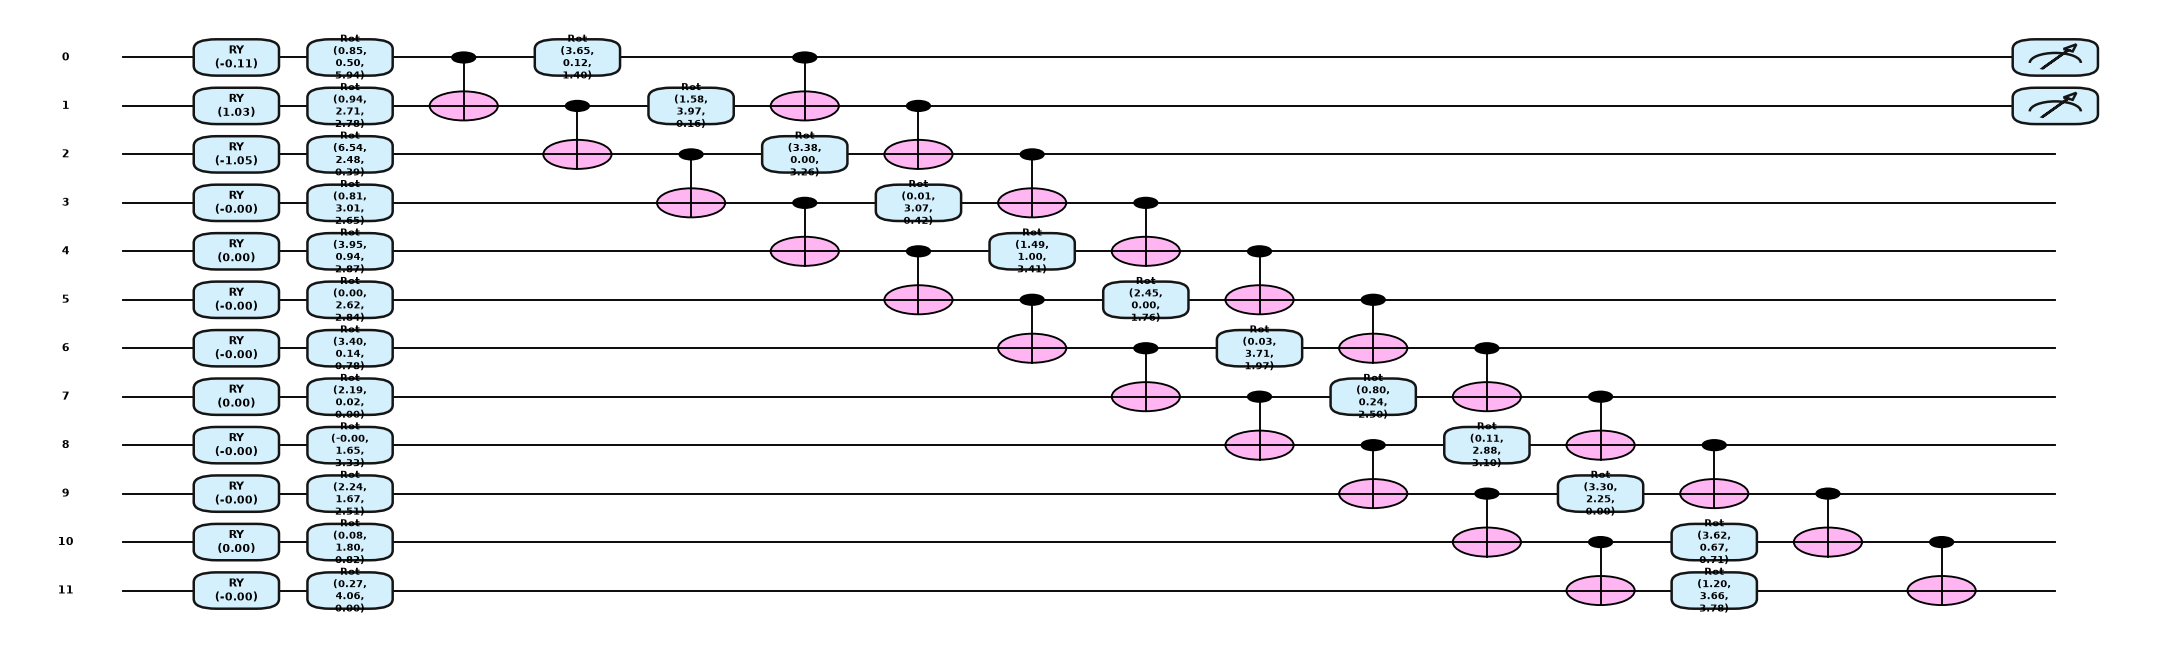

12-qubit circuit : 12 qubits, depth 16, 12 encoding RY + 24 trainable Rot + 22 CNOT, 72 trainable circuit parameters, measurements: <Z0>, <Z1>


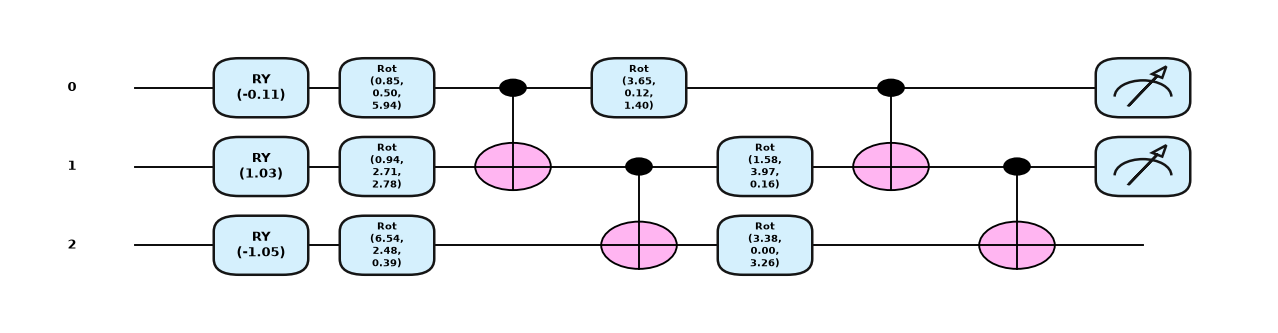

3-wire cone circuit: 3 qubits, depth 7, 13 gates, 18 trainable circuit parameters; its outcome distribution of qubits (0,1) feeds both the analytic prediction and the finite-shot sampler

Whole hybrid model : {'embedder': 1612, 'vqc': 72, 'head': 162, 'total': 1846}   [paper: 1,612 + 72 + 162 = 1,846]
assert OK: <Z0>,<Z1> of the drawn 12-qubit circuit == the 3-wire cone circuit == the torch simulator (trained weights, 32 random angle vectors)


In [11]:
ck = CKPTS[CKPT_KEYS[0]]
sp0 = SPLITS[(ck["protocol"], ck["seed"] if ck["protocol"] != "temporal" else None)]
x_demo = torch.tensor(sp0["test"]["X"][:1])
ang_demo = ck["model"].angles(x_demo).detach().double()                 # the 12 encoding angles of one real test flow
w_demo = ck["model"].weights.detach().double()                           # the trained rotation angles of this checkpoint
print("Encoding angles of one real test flow (rad):", np.round(ang_demo[0].numpy(), 3))

# Executed circuit 1: the paper's full 12-qubit QNode with the trained weights, drawn from the QNode itself
fig, ax = qml.draw_mpl(qnode12, decimals=2, style="pennylane", fontsize=9)(ang_demo[0], w_demo)
fig.set_size_inches(24, 7); plt.show()

# Resource counts from the tape that PennyLane actually executes
tape12 = qml.workflow.construct_tape(qnode12)(ang_demo[0], w_demo)
ops12 = [o.name for o in tape12.operations]
n_enc, n_rot, n_cnot = ops12.count("RY"), ops12.count("Rot"), ops12.count("CNOT")
res12 = qml.specs(qnode12)(ang_demo[0], w_demo)["resources"]
print(f"12-qubit circuit : {len(tape12.wires)} qubits, depth {res12.depth}, {n_enc} encoding RY + {n_rot} trainable Rot + {n_cnot} CNOT, "
      f"{3 * n_rot} trainable circuit parameters, measurements: <Z0>, <Z1>")
assert (n_enc, n_rot, n_cnot) == (12, 24, 22) and 3 * n_rot == PARAMS["vqc"]       # the paper: 12 / 24 / 22 gates, 72 parameters

# Executed circuit 2: the 3-wire backward-causal-cone circuit that carries all the information (used for training and sampling)
fig, ax = qml.draw_mpl(qnode3, decimals=2, style="pennylane", fontsize=10)(ang_demo[0, :3], w_demo[:, :3, :])
fig.set_size_inches(14, 3.5); plt.show()
tape3 = qml.workflow.construct_tape(qnode3)(ang_demo[0, :3], w_demo[:, :3, :]); res3 = qml.specs(qnode3)(ang_demo[0, :3], w_demo[:, :3, :])["resources"]
print(f"3-wire cone circuit: {len(tape3.wires)} qubits, depth {res3.depth}, {len(tape3.operations)} gates, "
      f"{3 * [o.name for o in tape3.operations].count('Rot')} trainable circuit parameters; its outcome distribution of qubits (0,1) feeds both the "
      f"analytic prediction and the finite-shot sampler")

print("\nWhole hybrid model :", PARAMS, "  [paper: 1,612 + 72 + 162 = 1,846]")
_a, _b = torch.rand(32, 12, dtype=torch.float64) * 2 - 1, ck["model"].weights.detach().double()
_full = torch.stack(qnode12(_a * math.pi, _b), dim=-1); _red = z_expectations(joint_probs_torch(_a * math.pi, _b))
assert torch.allclose(_full, _red, atol=1e-12)
print("assert OK: <Z0>,<Z1> of the drawn 12-qubit circuit == the 3-wire cone circuit == the torch simulator (trained weights, 32 random angle vectors)")

## 5. Is the finite-shot sampler really the circuit's measurement statistics?

The whole paper is about finite-shot estimates, so we check the sampler before using it. (1) PennyLane's own shot-based measurement of qubits 0 and 1 (20,000 shots, `qml.counts`) and (2) numpy's multinomial draw used in the policy must both reproduce the exact outcome probabilities;
(3) the estimate of $\langle Z\rangle$ must be unbiased with standard deviation $\sqrt{(1-\langle Z\rangle^2)/S}$, which is why 128 shots are noisy and 1024 are about 2.8 times less noisy.

In [12]:
STAGES = [128, 256, 512, 1024]; QUANTILES = [0.90, 0.95, 0.99]; PRIMARY_Q = 0.95; SMAX = STAGES[-1]
PROTO_CODE = {"random": 11, "group": 23, "temporal": 37}         # CHOICE: seed layout of the authors' code (base 73000)

@torch.no_grad()
def head_probability(model, meas):
    """Unchanged trained head on (possibly finite-shot) <Z0>, <Z1> estimates -> P(anomaly)."""
    return torch.softmax(model.head(torch.tensor(meas, dtype=torch.float32)), dim=1)[:, 1].double().numpy()

def counts_to_measurements(counts):
    s = counts.sum(1).astype(np.float64)
    p00, p01, p10, p11 = (counts[:, i] / s for i in range(4))
    return np.column_stack([p00 + p01 - p10 - p11, p00 - p01 + p10 - p11]).astype(np.float32)

def draw_counts(rng, joint, shots):
    """Real finite-shot sampling: `shots` projective measurements of qubits 0 and 1 give multinomial counts of
    the four outcomes 00, 01, 10, 11 drawn from the exact joint distribution."""
    sarr = np.full(len(joint), int(shots)) if np.isscalar(shots) else np.asarray(shots, np.int64)
    out = np.zeros((len(joint), 4), np.int64)
    for i, (p, s) in enumerate(zip(joint, sarr)):
        out[i] = rng.multinomial(int(s), p)
    return out

def ece_score(y, p, n_bins=15):
    ids = np.clip(np.digitize(p, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1)
    return float(sum(np.mean(ids == b) * abs(p[ids == b].mean() - y[ids == b].mean()) for b in range(n_bins) if np.any(ids == b)))

def policy_metrics(y, p, tau, p_an, shots):
    yh, ya = (p >= tau).astype(int), (p_an >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    d = p - p_an
    return dict(AUC=roc_auc_score(y, p), AP=average_precision_score(y, p), TPR=tp / max(tp + fn, 1), FPR=fp / max(fp + tn, 1),
                Brier=brier_score_loss(y, p), ECE=ece_score(y, p), ProbMAE=np.mean(np.abs(d)), ProbRMSE=np.sqrt(np.mean(d ** 2)),
                ProbBias=np.mean(d), Disagree=float(np.mean(yh != ya)), AvgShots=float(shots), Saving=1 - float(shots) / SMAX)

def calibrate_margins(model, joint_val, p_val, reps, rng):
    """Eqs. 9-10: delta_{S,beta} = beta-quantile of |p_hat - p| over validation records and replicates (S = 128, 256, 512)."""
    err = {s: np.concatenate([np.abs(head_probability(model, counts_to_measurements(draw_counts(rng, joint_val, s))) - p_val)
                              for _ in range(reps)]) for s in STAGES[:-1]}
    return {q: {s: float(np.quantile(err[s], q)) for s in STAGES[:-1]} for q in QUANTILES}

def adaptive_once(model, joint, tau, deltas, rng):
    """Eqs. 11-13: start at 128 shots, stop when |p_hat - tau*| > delta_S, otherwise acquire the extra shots needed to
    reach the next cumulative budget 256 -> 512 -> 1024; everything left at 1024 stops there."""
    n = len(joint); counts = np.zeros((n, 4), np.int64)
    final_p, final_s, active, prev = np.full(n, np.nan), np.zeros(n, np.int64), np.ones(n, bool), 0
    for stage in STAGES:
        idx = np.where(active)[0]
        if len(idx):
            counts[idx] += draw_counts(rng, joint[idx], stage - prev)     # cumulative: only the additional shots
            ph = head_probability(model, counts_to_measurements(counts[idx]))
            stop = np.ones(len(idx), bool) if stage == SMAX else np.abs(ph - tau) > deltas[stage]
            final_p[idx[stop]], final_s[idx[stop]], active[idx[stop]] = ph[stop], stage, False
        prev = stage
    assert not active.any() and np.isfinite(final_p).all()
    return final_p, final_s

In [13]:
# Finite-shot sampling is the heart of the paper, so it is checked against the real circuit before it is used.
# (1) PennyLane really measures qubits 0 and 1 of the 3-wire circuit with a finite number of shots,
# (2) the multinomial draw used by the policy has the same law (same mean and same spread).
ck = CKPTS[CKPT_KEYS[0]]
sp0 = SPLITS[(ck["protocol"], ck["seed"] if ck["protocol"] != "temporal" else None)]
X5 = torch.tensor(sp0["test"]["X"][:6])
ang5, w5 = ck["model"].angles(X5).detach().double(), ck["model"].weights.detach().double()
exact5 = joint_probs_torch(ang5, w5).numpy()
SHOTS_CHECK = 20_000
def circuit3_counts(a, w):
    for i in range(3):
        qml.RY(a[i], wires=i)
    for l in range(N_LAYERS):
        for i in range(3):
            qml.Rot(w[l, i, 0], w[l, i, 1], w[l, i, 2], wires=i)
        qml.CNOT(wires=[0, 1]); qml.CNOT(wires=[1, 2])
    return qml.counts(wires=[0, 1])

q3_counts = qml.set_shots(qml.QNode(circuit3_counts, qml.device("default.qubit", wires=3, seed=SEED)), shots=SHOTS_CHECK)
rng_chk = np.random.default_rng(SEED)
for i in range(len(exact5)):
    c = q3_counts(ang5[i, :3].numpy(), w5[:, :3, :].numpy())
    pl_freq = np.array([c.get(k, 0) for k in ("00", "01", "10", "11")]) / SHOTS_CHECK
    mn_freq = rng_chk.multinomial(SHOTS_CHECK, exact5[i]) / SHOTS_CHECK
    se = np.sqrt(exact5[i] * (1 - exact5[i]) / SHOTS_CHECK) + 1e-12
    print(f"record {i}: exact {np.round(exact5[i], 4)}  PennyLane shots {np.round(pl_freq, 4)}  multinomial {np.round(mn_freq, 4)}")
    assert np.all(np.abs(pl_freq - exact5[i]) < 5 * se + 2e-3), "PennyLane shot sampling disagrees with exact probabilities"
    assert np.all(np.abs(mn_freq - exact5[i]) < 5 * se + 2e-3), "multinomial sampling disagrees with exact probabilities"

# (3) unbiasedness and 1/sqrt(S) spread of the finite-shot <Z> estimate over many repetitions (policy sampling routine)
j_test = joint_probs_torch(ang5, w5).numpy(); z_exact = z_expectations(torch.tensor(j_test)).numpy()
for S in (128, 1024):
    est = np.stack([counts_to_measurements(draw_counts(rng_chk, j_test, S)) for _ in range(400)])      # (400, 6, 2)
    bias, sd = est.mean(0) - z_exact, est.std(0)
    sd_theory = np.sqrt(np.maximum(1 - z_exact ** 2, 0) / S)
    print(f"S={S:5d}: max |bias| {np.abs(bias).max():.4f}   max |sd - sqrt((1-<Z>^2)/S)| {np.abs(sd - sd_theory).max():.4f}")
    assert np.abs(bias).max() < 5 * sd_theory.max() / np.sqrt(400) + 1e-3
print("SAMPLING CHECK OK: finite-shot estimates are unbiased draws from the circuit's exact outcome distribution.")

record 0: exact [0.9429 0.0057 0.0472 0.0043]  PennyLane shots [0.9424 0.0056 0.047  0.005 ]  multinomial [0.9422 0.005  0.0486 0.0042]
record 1: exact [0.9186 0.0234 0.0502 0.0078]  PennyLane shots [0.9188 0.0229 0.0506 0.0077]  multinomial [0.9204 0.023  0.0484 0.0081]
record 2: exact [0.4161 0.5379 0.0153 0.0306]  PennyLane shots [0.4175 0.5365 0.0153 0.0307]  multinomial [0.4212 0.5347 0.0156 0.0284]


record 3: exact [0.6272 0.3062 0.0415 0.025 ]  PennyLane shots [0.6254 0.3078 0.0414 0.0254]  multinomial [0.6307 0.3031 0.0404 0.0257]
record 4: exact [0.8927 0.0729 0.0328 0.0017]  PennyLane shots [0.8918 0.0734 0.0331 0.0018]  multinomial [0.894  0.0728 0.0314 0.0018]
record 5: exact [0.833  0.11   0.0495 0.0074]  PennyLane shots [0.8322 0.1098 0.05   0.008 ]  multinomial [0.8318 0.1086 0.0516 0.0081]
S=  128: max |bias| 0.0059   max |sd - sqrt((1-<Z>^2)/S)| 0.0035
S= 1024: max |bias| 0.0029   max |sd - sqrt((1-<Z>^2)/S)| 0.0014
SAMPLING CHECK OK: finite-shot estimates are unbiased draws from the circuit's exact outcome distribution.


## 6. The adaptive-shot policies with real finite-shot sampling

For every checkpoint the cell below

1. rebuilds the exact joint outcome distribution of qubits 0 and 1 for each validation and test record and checks that the unchanged head turns it into the checkpoint's analytic probabilities,
2. calibrates the margins $\delta_{S,\beta}$ on the **validation** records only (`CAL_REPS` realizations per stage, eqs. 9-10),
3. for each of `MEAS_REPS` realizations evaluates the four fixed budgets, AS-VQC-90/95/99 and the **Budget-Shuffled-AS95** control, which keeps AS-VQC-95's final-shot histogram but assigns the budgets to random records, and
4. stores AUC, AP, TPR, FPR, Brier score, 15-bin ECE, probability errors, the decision disagreement $D = \frac1N\sum_i \mathbb 1[\mathbb 1(\hat p_i\ge\tau^*) \neq \mathbb 1(p_i\ge\tau^*)]$ (eq. 14), the average shots (eq. 15) and the saving $R_S = 1 - \bar S/1024$ (eq. 16).

Every "shot" is a draw from the circuit's outcome distribution: `rng.multinomial(S, [p00, p01, p10, p11])`. Acquisition is cumulative: a record that continues from 128 to 256 shots only gets 128 additional ones.

In [14]:
def evaluate_checkpoint(ck):
    protocol, seed, model, tau = ck["protocol"], ck["seed"], ck["model"], ck["tau"]
    sp = SPLITS[(protocol, seed if protocol != "temporal" else None)]
    yte = sp["test"]["y"]; model.eval()
    joint_val, joint_te = (model.joint(torch.tensor(sp[k]["X"])).numpy() for k in ("val", "test"))
    joint_val, joint_te = joint_val / joint_val.sum(1, keepdims=True), joint_te / joint_te.sum(1, keepdims=True)
    # reconstruction check: head(<Z>(joint)) must reproduce the model's analytic probabilities
    p_val = head_probability(model, z_expectations(torch.tensor(joint_val)).float().numpy())
    p_te = head_probability(model, z_expectations(torch.tensor(joint_te)).float().numpy())
    max_err = float(max(np.abs(p_val - ck["p_val"]).max(), np.abs(p_te - ck["p_test"]).max()))
    assert max_err < 1e-4, max_err
    base_seed = BASE_SEED + PROTO_CODE[protocol] * 1000 + seed
    margins = calibrate_margins(model, joint_val, p_val, CAL_REPS, np.random.default_rng(base_seed + 1))
    rows, allocs = [], []
    def add(policy, rep, p, shots_vec_or_value, alloc=None):
        shots = float(np.mean(shots_vec_or_value))
        m = policy_metrics(yte, p, tau, p_te, shots)
        for s in STAGES:
            m[f"Frac{s}"] = float(np.mean(alloc == s)) if alloc is not None else float(policy == f"Fixed-{s}")
        rows.append(dict(Protocol=protocol, Seed=seed, Policy=policy, Rep=rep, **m))
    for rep in range(MEAS_REPS):
        for s in STAGES:                                                      # uniform baselines
            rng = np.random.default_rng(base_seed + 100000 * rep + s)
            add(f"Fixed-{s}", rep, head_probability(model, counts_to_measurements(draw_counts(rng, joint_te, s))), s)
        by_q = {}
        for qi, q in enumerate(QUANTILES):                                    # AS-VQC-90 / 95 / 99
            rng = np.random.default_rng(base_seed + 200000 * rep + 1000 * qi + 17)
            ph, alloc = adaptive_once(model, joint_te, tau, margins[q], rng)
            by_q[q] = (ph, alloc); add(f"AS-VQC-{int(round(q * 100))}", rep, ph, alloc, alloc)
            if q == PRIMARY_Q:
                allocs.append(alloc.copy())
        rng = np.random.default_rng(base_seed + 300000 * rep + 29)             # matched-budget shuffled control
        shuffled = rng.permutation(by_q[PRIMARY_Q][1])
        add("Budget-Shuffled-AS95", rep, head_probability(model, counts_to_measurements(draw_counts(rng, joint_te, shuffled))), shuffled, shuffled)
    # the analytic (exact expectation) reference, once
    m = policy_metrics(yte, p_te, tau, p_te, 0.0); m["Saving"] = np.nan
    rows.append(dict(Protocol=protocol, Seed=seed, Policy="Analytic", Rep=-1, **m, **{f"Frac{s}": 0.0 for s in STAGES}))
    info = dict(Protocol=protocol, Seed=seed, tau=tau, recon_max_abs=max_err, margins=margins, joint_te=joint_te, p_te=p_te,
                y_te=yte, alloc95=np.stack(allocs), n_test=len(yte), n_val=len(p_val))
    return rows, info

t0, ROWS, INFO = time.time(), [], {}
for key in CKPT_KEYS:
    r, INFO[key] = evaluate_checkpoint(CKPTS[key]); ROWS += r
    i = INFO[key]
    print(f"{key[0]:8s} seed {key[1]}: tau* {i['tau']:.5f}  AS-VQC-95 mean shots "
          f"{np.mean([x['AvgShots'] for x in r if x['Policy']=='AS-VQC-95']):7.1f}  reconstruction max|err| {i['recon_max_abs']:.2e}  ({time.time()-t0:.0f} s)")
REAL = pd.DataFrame(ROWS)
print(len(REAL), "realization-level rows  (paper full matrix: 1,215 = 15 checkpoints x (1 analytic + 8 policies x 10 repetitions))")

random   seed 42: tau* 0.51688  AS-VQC-95 mean shots   129.1  reconstruction max|err| 1.79e-07  (1 s)


random   seed 43: tau* 0.72772  AS-VQC-95 mean shots   129.0  reconstruction max|err| 5.96e-08  (2 s)


random   seed 44: tau* 0.19230  AS-VQC-95 mean shots   129.7  reconstruction max|err| 5.96e-08  (4 s)


random   seed 45: tau* 0.41095  AS-VQC-95 mean shots   128.6  reconstruction max|err| 5.96e-08  (5 s)


random   seed 46: tau* 0.30662  AS-VQC-95 mean shots   129.5  reconstruction max|err| 5.96e-08  (6 s)


...

temporal seed 42: tau* 0.25281  AS-VQC-95 mean shots   131.2  reconstruction max|err| 5.96e-08  (14 s)


temporal seed 43: tau* 0.31241  AS-VQC-95 mean shots   128.2  reconstruction max|err| 5.96e-08  (15 s)


temporal seed 44: tau* 0.58367  AS-VQC-95 mean shots   133.2  reconstruction max|err| 5.96e-08  (16 s)


temporal seed 45: tau* 0.48852  AS-VQC-95 mean shots   132.9  reconstruction max|err| 5.96e-08  (17 s)


temporal seed 46: tau* 0.19081  AS-VQC-95 mean shots   130.5  reconstruction max|err| 5.96e-08  (19 s)
1215 realization-level rows  (paper full matrix: 1,215 = 15 checkpoints x (1 analytic + 8 policies x 10 repetitions))


## 7. Aggregation: the paper's Table 1 and the policy table

Repetitions are averaged inside each checkpoint; mean and sample standard deviation are then taken over the checkpoints (so the "$\pm$" measures checkpoint-to-checkpoint variability, not sampling noise).
Paired comparisons use a percentile bootstrap (10,000 resamples) of the per-checkpoint differences. With only two checkpoints (`FAST_MODE`) the intervals are not meaningful.

In [15]:
# Seed-level aggregation (paper section 3.7): average the finite-shot repetitions inside each trained checkpoint,
# then report mean +/- sample SD over the checkpoints.  The analytic reference row is kept separately.
FIN = REAL[REAL.Policy != "Analytic"]
METRICS = ["AUC", "AP", "TPR", "FPR", "Brier", "ECE", "ProbMAE", "ProbRMSE", "ProbBias", "Disagree", "AvgShots", "Saving",
           "Frac128", "Frac256", "Frac512", "Frac1024"]
SEED_LEVEL = FIN.groupby(["Protocol", "Seed", "Policy"])[METRICS].mean().reset_index()
ANALYTIC = REAL[REAL.Policy == "Analytic"].set_index(["Protocol", "Seed"])
POLICIES = ["Fixed-128", "Fixed-256", "Fixed-512", "Fixed-1024", "AS-VQC-90", "AS-VQC-95", "AS-VQC-99", "Budget-Shuffled-AS95"]
SUMMARY = SEED_LEVEL.groupby(["Protocol", "Policy"])[METRICS].agg(["mean", "std"])
def S(protocol, policy, metric, stat="mean"):
    return float(SUMMARY.loc[(protocol, policy), (metric, stat)])
PROTO_NAMES = {"random": "Random", "group": "Group", "temporal": "Temporal"}

# Table 1 of the paper: AS-VQC-95
t1 = []
for pr in PROTOCOLS:
    t1.append({"Holdout": PROTO_NAMES[pr], "seeds": int(SEED_LEVEL[(SEED_LEVEL.Protocol == pr) & (SEED_LEVEL.Policy == "AS-VQC-95")].shape[0]),
               **{m: f"{S(pr,'AS-VQC-95',m):.4f} +/- {S(pr,'AS-VQC-95',m,'std'):.4f}" for m in ["AUC", "AP", "FPR", "ECE"]},
               "Disagree %": f"{100*S(pr,'AS-VQC-95','Disagree'):.3f} +/- {100*S(pr,'AS-VQC-95','Disagree','std'):.3f}",
               "Average shots": f"{S(pr,'AS-VQC-95','AvgShots'):.1f} +/- {S(pr,'AS-VQC-95','AvgShots','std'):.1f}",
               "Saving %": f"{100*S(pr,'AS-VQC-95','Saving'):.2f} +/- {100*S(pr,'AS-VQC-95','Saving','std'):.2f}"})
print("Notebook version of the paper's Table 1 (AS-VQC-95, mean +/- sample SD over checkpoints):")
display(pd.DataFrame(t1).set_index("Holdout"))

# All policies, all holdouts
rows = []
for pr in PROTOCOLS:
    for pol in POLICIES:
        rows.append({"Holdout": PROTO_NAMES[pr], "Policy": pol, "AUC": S(pr, pol, "AUC"), "AUC loss vs analytic (1e-4)": 1e4 * (np.mean([ANALYTIC.loc[(pr, s), "AUC"] for s in SEEDS]) - S(pr, pol, "AUC")),
                     "TPR": S(pr, pol, "TPR"), "FPR": S(pr, pol, "FPR"), "ECE": S(pr, pol, "ECE"), "Disagree %": 100 * S(pr, pol, "Disagree"),
                     "Avg shots": S(pr, pol, "AvgShots"), "Saving %": 100 * S(pr, pol, "Saving")})
POLICY_TABLE = pd.DataFrame(rows)
display(POLICY_TABLE.round(4))

# Paired percentile bootstrap over the seed-level differences (10,000 resamples), as in the paper
def paired_bootstrap(a, b, reps=BOOT_REPS, seed=2026):
    d = np.asarray(a) - np.asarray(b)
    rng = np.random.default_rng(seed)
    means = d[rng.integers(0, len(d), size=(reps, len(d)))].mean(1)
    return float(d.mean()), float(np.quantile(means, 0.025)), float(np.quantile(means, 0.975))

def seedvec(pr, pol, metric):
    sub = SEED_LEVEL[(SEED_LEVEL.Protocol == pr) & (SEED_LEVEL.Policy == pol)].sort_values("Seed")
    return sub[metric].to_numpy()

PAIRED = {}
for pr in PROTOCOLS:
    for comp in ["Fixed-128", "Budget-Shuffled-AS95", "Fixed-1024"]:
        PAIRED[(pr, comp)] = paired_bootstrap(100 * seedvec(pr, "AS-VQC-95", "Disagree"), 100 * seedvec(pr, comp, "Disagree"))
pb = pd.DataFrame([{"Holdout": PROTO_NAMES[pr], "AS-VQC-95 minus": comp, "mean diff (pp)": v[0], "95% CI low": v[1], "95% CI high": v[2]}
                   for (pr, comp), v in PAIRED.items()])
print("Paired differences in decision disagreement (percentage points):")
display(pb.round(3))

Notebook version of the paper's Table 1 (AS-VQC-95, mean +/- sample SD over checkpoints):


,seeds,AUC,AP,FPR,ECE,Disagree %,Average shots,Saving %
Holdout,,,,,,,,
Random,5,0.9955 +/- 0.0015,0.9757 +/- 0.0056,0.0319 +/- 0.0061,0.0271 +/- 0.0072,0.882 +/- 0.227,129.2 +/- 0.4,87.39 +/- 0.04
Group,5,0.9969 +/- 0.0018,0.9839 +/- 0.0092,0.0362 +/- 0.0342,0.0175 +/- 0.0038,0.400 +/- 0.094,276.1 +/- 325.9,73.04 +/- 31.83
Temporal,5,0.9980 +/- 0.0010,0.9895 +/- 0.0060,0.0252 +/- 0.0104,0.0211 +/- 0.0076,0.638 +/- 0.097,131.2 +/- 2.0,87.19 +/- 0.20


,Holdout,Policy,AUC,AUC loss vs analytic (1e-4),TPR,FPR,ECE,Disagree %,Avg shots,Saving %
0,Random,Fixed-128,0.9954,7.8047,0.9675,0.0340,0.0277,1.0665,128.0000,87.5000
1,Random,Fixed-256,0.9959,3.2518,0.9707,0.0326,0.0264,0.7305,256.0000,75.0000
2,Random,Fixed-512,0.9960,1.5377,0.9722,0.0322,0.0272,0.5169,512.0000,50.0000
3,Random,Fixed-1024,0.9961,0.6723,0.9759,0.0323,0.0263,0.3526,1024.0000,0.0000
4,Random,AS-VQC-90,0.9955,6.6258,0.9646,0.0332,0.0275,1.0544,128.1905,87.4814
5,Random,AS-VQC-95,0.9955,7.1646,0.9703,0.0319,0.0271,0.8819,129.1748,87.3853
6,Random,AS-VQC-99,0.9958,4.2129,0.9760,0.0324,0.0271,0.4484,163.6757,84.0160
7,Random,Budget-Shuffled-AS95,0.9956,6.2389,0.9688,0.0331,0.0272,1.0174,129.1748,87.3853
8,Group,Fixed-128,0.9966,7.8375,0.9793,0.0362,0.0168,0.7062,128.0000,87.5000
9,Group,Fixed-256,0.9970,3.4252,0.9801,0.0354,0.0169,0.4537,256.0000,75.0000


Paired differences in decision disagreement (percentage points):


,Holdout,AS-VQC-95 minus,mean diff (pp),95% CI low,95% CI high
0,Random,Fixed-128,-0.185,-0.276,-0.086
1,Random,Budget-Shuffled-AS95,-0.136,-0.230,-0.037
2,Random,Fixed-1024,0.529,0.427,0.668
3,Group,Fixed-128,-0.306,-0.577,-0.056
4,Group,Budget-Shuffled-AS95,-0.192,-0.352,-0.083
5,Group,Fixed-1024,0.207,0.092,0.294
6,Temporal,Fixed-128,-0.377,-0.562,-0.126
7,Temporal,Budget-Shuffled-AS95,-0.364,-0.572,-0.106
8,Temporal,Fixed-1024,0.294,0.258,0.334


## 8. Re-drawing the paper's figures

(Fig. 2) AUC loss and decision disagreement against the average number of shots; (Fig. 3) targeted versus shuffled allocation and the TPR/FPR operating points; (Fig. 4) where the shots go and how close to the threshold the escalated records are;
(Fig. 5) calibration against the budget and per-checkpoint demand; and, last, the *learned* encoding angles of real test flows coloured by label.

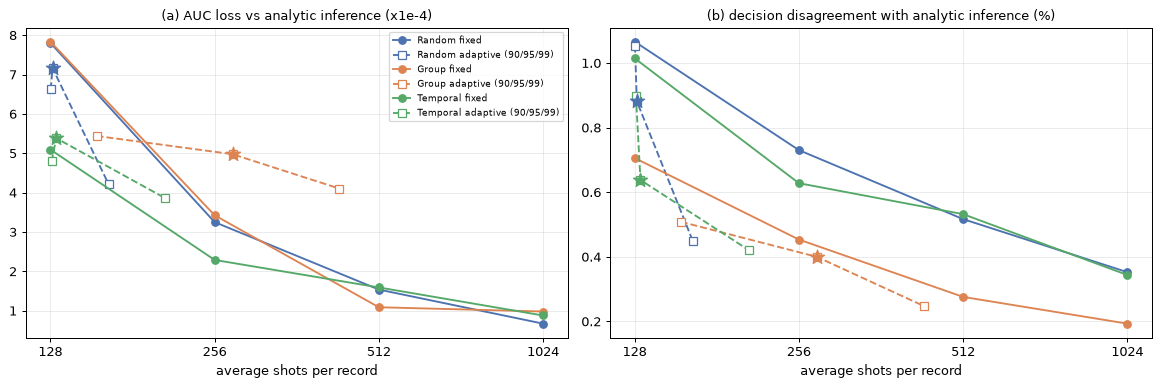

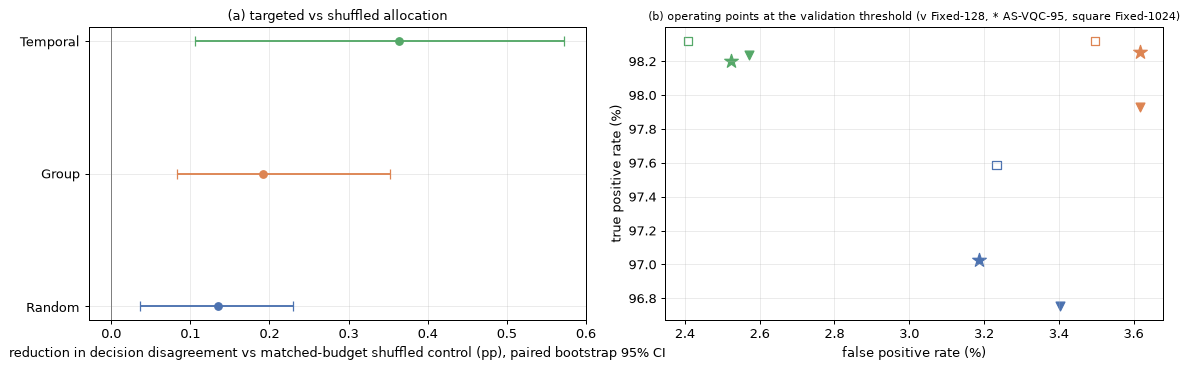

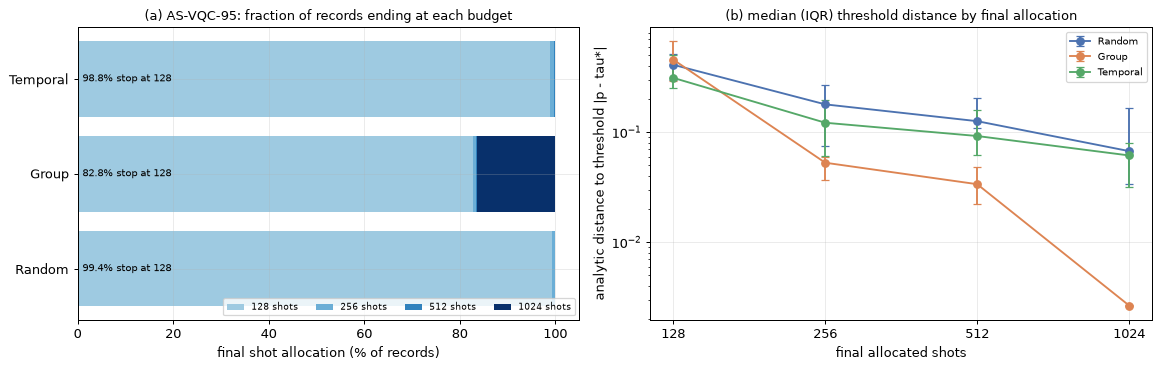

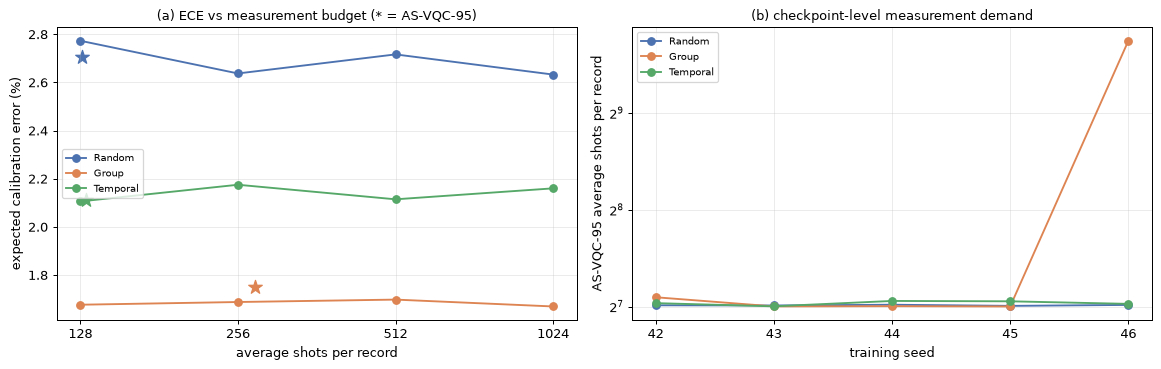

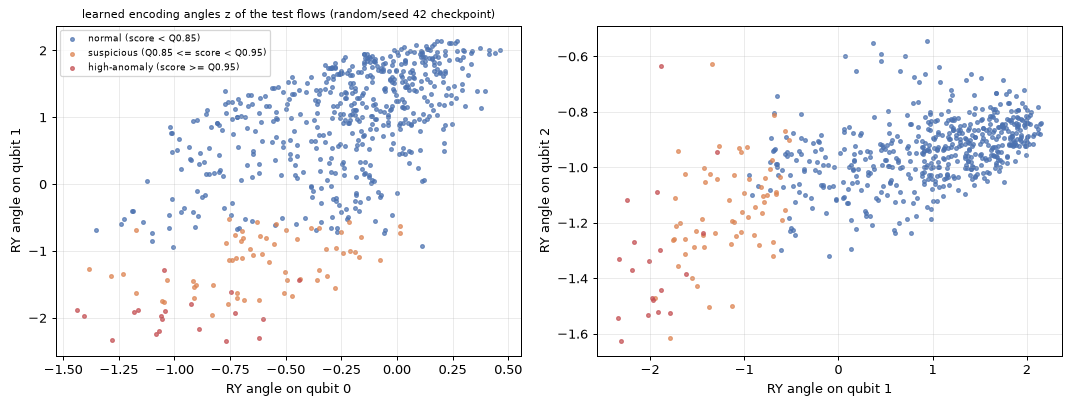

In [16]:
PCOL = {"random": "#4c72b0", "group": "#dd8452", "temporal": "#55a868"}
fixed = ["Fixed-128", "Fixed-256", "Fixed-512", "Fixed-1024"]
def lookup(pr, pol, col): return float(POLICY_TABLE[(POLICY_TABLE.Holdout == PROTO_NAMES[pr]) & (POLICY_TABLE.Policy == pol)][col].iloc[0])

# ---- Figure 2 of the paper: ranking preservation and decision reliability vs measurement budget ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for pr in PROTOCOLS:
    xs = [lookup(pr, p, "Avg shots") for p in fixed]
    for ax, col in zip(axes, ["AUC loss vs analytic (1e-4)", "Disagree %"]):
        ax.plot(xs, [lookup(pr, p, col) for p in fixed], "o-", color=PCOL[pr], label=f"{PROTO_NAMES[pr]} fixed")
        ax.plot([lookup(pr, p, "Avg shots") for p in ["AS-VQC-90", "AS-VQC-95", "AS-VQC-99"]],
                [lookup(pr, p, col) for p in ["AS-VQC-90", "AS-VQC-95", "AS-VQC-99"]], "s--", color=PCOL[pr], mfc="white", label=f"{PROTO_NAMES[pr]} adaptive (90/95/99)")
        ax.scatter([lookup(pr, "AS-VQC-95", "Avg shots")], [lookup(pr, "AS-VQC-95", col)], s=140, marker="*", color=PCOL[pr], zorder=5)
for ax, t in zip(axes, ["(a) AUC loss vs analytic inference (x1e-4)", "(b) decision disagreement with analytic inference (%)"]):
    ax.set_xscale("log", base=2); ax.set_xticks([128, 256, 512, 1024]); ax.set_xticklabels([128, 256, 512, 1024])
    ax.set_xlabel("average shots per record"); ax.set_title(t, fontsize=10)
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

# ---- Figure 3 of the paper: targeted vs shuffled allocation, TPR/FPR operating points ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for i, pr in enumerate(PROTOCOLS):
    m, lo, hi = PAIRED[(pr, "Budget-Shuffled-AS95")]
    axes[0].errorbar([-m], [i], xerr=[[-m - (-hi)], [(-lo) - (-m)]], fmt="o", color=PCOL[pr], capsize=4)
    axes[1].scatter(100 * lookup(pr, "Fixed-128", "FPR"), 100 * lookup(pr, "Fixed-128", "TPR"), marker="v", color=PCOL[pr], s=50)
    axes[1].scatter(100 * lookup(pr, "AS-VQC-95", "FPR"), 100 * lookup(pr, "AS-VQC-95", "TPR"), marker="*", color=PCOL[pr], s=130)
    axes[1].scatter(100 * lookup(pr, "Fixed-1024", "FPR"), 100 * lookup(pr, "Fixed-1024", "TPR"), marker="s", color=PCOL[pr], s=45, facecolors="none")
axes[0].axvline(0, color="grey", lw=.8); axes[0].set_yticks(range(3)); axes[0].set_yticklabels([PROTO_NAMES[p] for p in PROTOCOLS])
axes[0].set_xlabel("reduction in decision disagreement vs matched-budget shuffled control (pp), paired bootstrap 95% CI"); axes[0].set_title("(a) targeted vs shuffled allocation", fontsize=10)
axes[1].set_xlabel("false positive rate (%)"); axes[1].set_ylabel("true positive rate (%)"); axes[1].set_title("(b) operating points at the validation threshold (v Fixed-128, * AS-VQC-95, square Fixed-1024)", fontsize=9)
plt.tight_layout(); plt.show()

# ---- Figure 4 of the paper: where the shots go ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
stack_cols = {128: "#9ecae1", 256: "#6baed6", 512: "#3182bd", 1024: "#08306b"}
for i, pr in enumerate(PROTOCOLS):
    left = 0.0
    for s in STAGES:
        v = 100 * S(pr, "AS-VQC-95", f"Frac{s}")
        axes[0].barh(i, v, left=left, color=stack_cols[s], label=f"{s} shots" if i == 0 else None); left += v
    axes[0].text(1, i, f"{100*S(pr,'AS-VQC-95','Frac128'):.1f}% stop at 128", va="center", fontsize=8, color="black")
axes[0].set_yticks(range(3)); axes[0].set_yticklabels([PROTO_NAMES[p] for p in PROTOCOLS]); axes[0].set_xlabel("final shot allocation (% of records)")
axes[0].set_title("(a) AS-VQC-95: fraction of records ending at each budget", fontsize=10); axes[0].legend(fontsize=7, ncol=4, loc="lower right")
DIST = {}
for pr in PROTOCOLS:
    d_all, a_all = [], []
    for key in CKPT_KEYS:
        if key[0] != pr: continue
        inf = INFO[key]; d = np.abs(inf["p_te"] - inf["tau"])
        d_all.append(np.tile(d, (inf["alloc95"].shape[0], 1)).ravel()); a_all.append(inf["alloc95"].ravel())
    d_all, a_all = np.concatenate(d_all), np.concatenate(a_all)
    DIST[pr] = {s: (np.median(d_all[a_all == s]), *np.quantile(d_all[a_all == s], [.25, .75])) if np.any(a_all == s) else (np.nan,) * 3 for s in STAGES}
    xs = [s for s in STAGES if np.any(a_all == s)]
    med = np.array([DIST[pr][s][0] for s in xs]); q1 = np.array([DIST[pr][s][1] for s in xs]); q3 = np.array([DIST[pr][s][2] for s in xs])
    axes[1].errorbar(xs, med, yerr=[med - q1, q3 - med], fmt="o-", color=PCOL[pr], capsize=3, label=PROTO_NAMES[pr])
axes[1].set_xscale("log", base=2); axes[1].set_yscale("log"); axes[1].set_xticks(STAGES); axes[1].set_xticklabels(STAGES)
axes[1].set_xlabel("final allocated shots"); axes[1].set_ylabel("analytic distance to threshold |p - tau*|"); axes[1].legend(fontsize=8)
axes[1].set_title("(b) median (IQR) threshold distance by final allocation", fontsize=10)
plt.tight_layout(); plt.show()

# ---- Figure 5 of the paper: calibration vs shots and per-checkpoint resource demand ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for pr in PROTOCOLS:
    axes[0].plot([lookup(pr, p, "Avg shots") for p in fixed], [100 * lookup(pr, p, "ECE") for p in fixed], "o-", color=PCOL[pr], label=PROTO_NAMES[pr])
    axes[0].scatter([lookup(pr, "AS-VQC-95", "Avg shots")], [100 * lookup(pr, "AS-VQC-95", "ECE")], marker="*", s=130, color=PCOL[pr])
    sub = SEED_LEVEL[(SEED_LEVEL.Protocol == pr) & (SEED_LEVEL.Policy == "AS-VQC-95")].sort_values("Seed")
    axes[1].plot(sub.Seed, sub.AvgShots, "o-", color=PCOL[pr], label=PROTO_NAMES[pr])
axes[0].set_xscale("log", base=2); axes[0].set_xticks(STAGES); axes[0].set_xticklabels(STAGES); axes[0].set_xlabel("average shots per record")
axes[0].set_ylabel("expected calibration error (%)"); axes[0].set_title("(a) ECE vs measurement budget (* = AS-VQC-95)", fontsize=10); axes[0].legend(fontsize=8)
axes[1].set_yscale("log", base=2); axes[1].set_xlabel("training seed"); axes[1].set_ylabel("AS-VQC-95 average shots per record")
axes[1].set_title("(b) checkpoint-level measurement demand", fontsize=10); axes[1].set_xticks(SEEDS); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---- The learned encoding angles of real test flows, coloured by ground-truth label (what the VQC actually receives) ----
ck = CKPTS[("random", 42)] if ("random", 42) in CKPTS else CKPTS[CKPT_KEYS[0]]
sp = SPLITS[(ck["protocol"], ck["seed"] if ck["protocol"] != "temporal" else None)]
with torch.no_grad():
    ang = ck["model"].angles(torch.tensor(sp["test"]["X"])).numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for lab in (0, 1, 2):
    m = sp["test"]["y3"] == lab
    axes[0].scatter(ang[m, 0], ang[m, 1], s=9, alpha=.7, color=LABEL_COLORS[lab], label=LABEL_NAMES[lab])
    axes[1].scatter(ang[m, 1], ang[m, 2], s=9, alpha=.7, color=LABEL_COLORS[lab])
axes[0].set_xlabel("RY angle on qubit 0"); axes[0].set_ylabel("RY angle on qubit 1"); axes[1].set_xlabel("RY angle on qubit 1"); axes[1].set_ylabel("RY angle on qubit 2")
axes[0].set_title(f"learned encoding angles z of the test flows ({ck['protocol']}/seed {ck['seed']} checkpoint)", fontsize=9); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Classical baselines on identical inputs

The paper compares only quantum policies. To judge the *scorer* itself we train, on exactly the same 12 robust-scaled features and the same splits, a random forest, an RBF support-vector machine and a "classical twin" of the network
(same embedder, angle bounding, head and recipe, but the 12-qubit circuit is replaced by a trainable linear map 12 -> 2). Thresholds are again chosen by Youden's J on the validation split. We also add an **oracle**: because the pseudo-label is *defined* as a threshold on the L2 norm of the scaled features, that norm separates the classes perfectly
by construction. This is the single most important caveat for reading the QNN's 0.995-0.999 AUC.

In [17]:
# Classical baselines on EXACTLY the same inputs (the 12 robust-scaled features of each split) and the same
# protocol: train on the training split, threshold (Youden J) on the validation split, evaluate on the test split.
def op_metrics(y, score, tau):
    yh = (score >= tau).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return dict(AUC=roc_auc_score(y, score), AP=average_precision_score(y, score), TPR=tp / max(tp + fn, 1), FPR=fp / max(fp + tn, 1))

BASE, t0 = [], time.time()
for key in CKPT_KEYS:
    pr, sd = key; sp = SPLITS[(pr, sd if pr != "temporal" else None)]
    Xtr, ytr, Xva, yva, Xte, yte = (sp[k][v] for k in ("train", "val", "test") for v in ("X", "y"))
    ck = CKPTS[key]
    BASE.append(dict(Protocol=pr, Seed=sd, Model="hybrid QNN (analytic, 12 qubits)", **op_metrics(yte, ck["p_test"], ck["tau"])))
    models = {"RandomForest (300 trees)": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=1),
              "SVC (RBF, C=1)": SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=SEED)}
    for name, clf in models.items():
        clf.fit(Xtr, ytr)
        f = (lambda X: clf.predict_proba(X)[:, 1]) if hasattr(clf, "predict_proba") and name.startswith("Random") else clf.decision_function
        tau = youden_threshold(yva, f(Xva))
        BASE.append(dict(Protocol=pr, Seed=sd, Model=name, **op_metrics(yte, f(Xte), tau)))
    tw = train_checkpoint(pr, sd, classical_twin=True)                         # same embedder/head/recipe, classical 12->2 layer instead of the VQC
    BASE.append(dict(Protocol=pr, Seed=sd, Model="classical twin (VQC replaced by Linear 12->2)", **op_metrics(yte, tw["p_test"], tw["tau"])))
    # oracle: the label is a deterministic function of the features, so the anomaly score itself separates the classes perfectly
    BASE.append(dict(Protocol=pr, Seed=sd, Model="oracle: the L2-norm score used to make the labels", **op_metrics(yte, sp["test"]["score"], float(sp["params"]["t_susp"]))))
    print(f"{pr:8s} seed {sd}: baselines done ({time.time()-t0:.0f} s)")
BASELINES = pd.DataFrame(BASE)
agg = BASELINES.groupby(["Protocol", "Model"])[["AUC", "AP", "TPR", "FPR"]].agg(["mean", "std"])
print("\nTest-set results on identical inputs (mean over checkpoints; the hybrid QNN row is the exact-expectation 'analytic' inference):")
display(agg.round(4))

random   seed 42: baselines done (7 s)


random   seed 43: baselines done (14 s)


random   seed 44: baselines done (20 s)


random   seed 45: baselines done (27 s)


random   seed 46: baselines done (31 s)


...

temporal seed 43: baselines done (66 s)


temporal seed 44: baselines done (72 s)


temporal seed 45: baselines done (77 s)


temporal seed 46: baselines done (82 s)

Test-set results on identical inputs (mean over checkpoints; the hybrid QNN row is the exact-expectation 'analytic' inference):


AUC          \
                                                              mean     std   
Protocol Model                                                               
group    RandomForest (300 trees)                           0.9842  0.0041   
         SVC (RBF, C=1)                                     0.9980  0.0012   
         classical twin (VQC replaced by Linear 12->2)      0.9977  0.0013   
         hybrid QNN (analytic, 12 qubits)                   0.9974  0.0015   
         oracle: the L2-norm score used to make the labels  1.0000  0.0000   
random   RandomForest (300 trees)                           0.9840  0.0050   
         SVC (RBF, C=1)                                     0.9977  0.0011   
         classical twin (VQC replaced by Linear 12->2)      0.9973  0.0008   
         hybrid QNN (analytic, 12 qubits)                   0.9962  0.0014   
         oracle: the L2-norm score used to make the labels  1.0000  0.0000   
temporal RandomForest (300 trees)                           0.9909  0.0000   
         SVC (RBF, C=1)                                     0.9993  0.0000   
         classical twin (VQC replaced by Linear 12->2)      0.9993  0.0002   
         hybrid QNN (analytic, 12 qubits)                   0.9985  0.0008   
         oracle: the L2-norm score used to make the labels  1.0000  0.0000   

                                                                AP          \
                                                              mean     std   
Protocol Model                                                               
group    RandomForest (300 trees)                           0.9042  0.0214   
         SVC (RBF, C=1)                                     0.9879  0.0072   
         classical twin (VQC replaced by Linear 12->2)      0.9864  0.0078   
         hybrid QNN (analytic, 12 qubits)                   0.9863  0.0081   
         oracle: the L2-norm score used to make the labels  1.0000  0.0000   
random   RandomForest (300 trees)                           0.9133  0.0313   
         SVC (RBF, C=1)                                     0.9867  0.0053   
         classical twin (VQC replaced by Linear 12->2)      0.9848  0.0026   
         hybrid QNN (analytic, 12 qubits)                   0.9794  0.0050   
         oracle: the L2-norm score used to make the labels  1.0000  0.0000   
temporal RandomForest (300 trees)                           0.9579  0.0000   
         SVC (RBF, C=1)                                     0.9965  0.0000   
         classical twin (VQC replaced by Linear 12->2)      0.9965  0.0012   
         hybrid QNN (analytic, 12 qubits)                   0.9920  0.0054   
         oracle: the L2-norm score used to make the labels  1.0000  0.0000   

                                                               TPR          \
                                                              mean     std   
Protocol Model                                                               
group    RandomForest (300 trees)                           0.9789  0.0252   
         SVC (RBF, C=1)                                     0.9707  0.0502   
         classical twin (VQC replaced by Linear 12->2)      0.9840  0.0112   
         hybrid QNN (analytic, 12 qubits)                   0.9835  0.0182   
         oracle: the L2-norm score used to make the labels  1.0000  0.0000   
random   RandomForest (300 trees)                           0.9391  0.0479   
         SVC (RBF, C=1)                                     0.9884  0.0150   
         classical twin (VQC replaced by Linear 12->2)      0.9596  0.0248   
         hybrid QNN (analytic, 12 qubits)                   0.9801  0.0208   
         oracle: the L2-norm score used to make the labels  1.0000  0.0000   
temporal RandomForest (300 trees)                           0.9500  0.0000   
         SVC (RBF, C=1)                                     0.9900  0.0000   
         classical twin (VQC replaced by Linear 12->2)      0.9700  0.0122   
     

## 10. Side-by-side comparison with the paper and a verdict per claim

A claim is **reproduced** when our value lies within the tolerance of the paper's (0.02 for AUC/AP/FPR/ECE and probabilities, 2 percentage points for percentages and shot savings, 20.5 shots for shot counts, 2e-4 for the AUC-loss bound; exact match for counts), **not reached** / **exceeded** when it is worse / better by more than the tolerance,
and **cannot be checked** when the quantity does not exist in this run (for example group seed 46 in `FAST_MODE`). Directional claims ("less disagreement than Fixed-128, interval excludes zero") are reproduced when the sign and the bootstrap interval agree with the paper.
Note that a 2-point tolerance is generous for AUC (all AUCs are about 0.995 to 0.999) and for disagreement (all below 1 %); the `gap` column shows the real difference and `within_eighth_of_tol` flags the claims that are also inside one eighth of the tolerance.

In [18]:
TOL_POINTS = 0.02          # accuracy-type metrics (AUC, AP, FPR, ECE): 2 points on the 0-1 scale
TOL_PP = 2.0               # percentage-point quantities (savings, disagreement %, share of records): 2 pp
CLAIMS = []

def numeric_claim(claim, holdout, paper, mine, tol, unit, higher_is_better):
    if mine is None or not np.isfinite(mine):
        verdict, gap = "cannot be checked", np.nan
    else:
        gap = mine - paper
        if abs(gap) <= tol: verdict = "reproduced"
        else: verdict = ("exceeded" if (gap > 0) == higher_is_better else "not reached")
    CLAIMS.append(dict(claim=claim, holdout=holdout, paper=paper, notebook=None if mine is None else round(float(mine), 4), gap=None if mine is None else round(float(gap), 4), tolerance=f"{tol} {unit}", within_eighth_of_tol=(None if mine is None else bool(abs(gap) <= tol / 8)), verdict=verdict))

def directional_claim(claim, holdout, paper_text, mine_text, ok):
    CLAIMS.append(dict(claim=claim, holdout=holdout, paper=paper_text, notebook=mine_text, gap="", tolerance="same sign / CI",
                       verdict="cannot be checked" if ok is None else ("reproduced" if ok else "not reached")))

# Paper numbers (abstract, Table 1, section 4, appendix)
P = {"random":   dict(AUC=.9956, AP=.9760, FPR=.0299, ECE=.0257, dis=.771, shots=129.2, sav=87.39, f128=99.44, sh99=162.6, dis99=.407, dis512=.462, d128=-.142, dshuf=-.129, d1024=.435, dist=(.411, .060)),
     "group":    dict(AUC=.9968, AP=.9835, FPR=.0346, ECE=.0174, dis=.409, shots=276.9, sav=72.96, f128=82.75, sh99=432.9, dis99=.248, dis512=.333, d128=-.396, dshuf=-.196, d1024=.210, dist=(.458, .005)),
     "temporal": dict(AUC=.9980, AP=.9895, FPR=.0252, ECE=.0211, dis=.635, shots=131.2, sav=87.19, f128=98.83, sh99=207.7, dis99=.423, dis512=.532, d128=-.380, dshuf=-.367, d1024=.281, dist=(.312, .062))}
for pr in PROTOCOLS:
    h, p = PROTO_NAMES[pr], P[pr]
    for m, hib in (("AUC", True), ("AP", True), ("FPR", False), ("ECE", False)):
        numeric_claim(f"AS-VQC-95 {m} (Table 1)", h, p[m], S(pr, "AS-VQC-95", m), TOL_POINTS, "abs", hib)
    numeric_claim("AS-VQC-95 decision disagreement % (abstract)", h, p["dis"], 100 * S(pr, "AS-VQC-95", "Disagree"), TOL_PP, "pp", False)
    numeric_claim("AS-VQC-95 saving vs Fixed-1024 % (Table 1)", h, p["sav"], 100 * S(pr, "AS-VQC-95", "Saving"), TOL_PP, "pp", True)
    numeric_claim("AS-VQC-95 average shots per record (Table 1; derived tolerance 2 pp of 1024 = 20.5 shots)", h, p["shots"], S(pr, "AS-VQC-95", "AvgShots"), 0.02 * SMAX, "shots", False)
    numeric_claim("share of records stopping at 128 shots % (Fig. 4a)", h, p["f128"], 100 * S(pr, "AS-VQC-95", "Frac128"), TOL_PP, "pp", True)
    numeric_claim("AS-VQC-99 saving % (from 162.6 / 432.9 / 207.7 shots)", h, 100 * (1 - p["sh99"] / SMAX), 100 * S(pr, "AS-VQC-99", "Saving"), TOL_PP, "pp", True)
    numeric_claim("AS-VQC-99 decision disagreement % (section 4.3)", h, p["dis99"], 100 * S(pr, "AS-VQC-99", "Disagree"), TOL_PP, "pp", False)
    numeric_claim("Fixed-512 decision disagreement % (section 4.3)", h, p["dis512"], 100 * S(pr, "Fixed-512", "Disagree"), TOL_PP, "pp", False)
    # directional claims with the paper's paired bootstrap CIs
    m, lo, hi = PAIRED[(pr, "Fixed-128")]
    directional_claim("AS-VQC-95 reduces disagreement vs Fixed-128 (CI excludes 0)", h, f"{p['d128']:+.3f} pp, CI excludes 0", f"{m:+.3f} pp [{lo:+.3f}, {hi:+.3f}]", (m < 0 and hi < 0) if len(SEEDS) > 2 else None)
    m, lo, hi = PAIRED[(pr, "Budget-Shuffled-AS95")]
    directional_claim("AS-VQC-95 beats the matched-budget shuffled control (CI excludes 0)", h, f"{p['dshuf']:+.3f} pp, CI excludes 0", f"{m:+.3f} pp [{lo:+.3f}, {hi:+.3f}]", (m < 0 and hi < 0) if len(SEEDS) > 2 else None)
    m, lo, hi = PAIRED[(pr, "Fixed-1024")]
    directional_claim("Fixed-1024 stays more stable than AS-VQC-95 (CI above 0)", h, f"{p['d1024']:+.3f} pp, CI above 0", f"{m:+.3f} pp [{lo:+.3f}, {hi:+.3f}]", (m > 0 and lo > 0) if len(SEEDS) > 2 else None)
    ok99 = S(pr, "AS-VQC-99", "AvgShots") < 512 and S(pr, "AS-VQC-99", "Disagree") < S(pr, "Fixed-512", "Disagree")
    directional_claim("AS-VQC-99 uses < 512 shots and has lower disagreement than Fixed-512", h, "yes", f"{S(pr,'AS-VQC-99','AvgShots'):.1f} shots; {100*S(pr,'AS-VQC-99','Disagree'):.3f}% vs {100*S(pr,'Fixed-512','Disagree'):.3f}%", ok99)
    d = DIST[pr]
    numeric_claim("median threshold distance of records ending at 128 shots", h, p["dist"][0], d[128][0], TOL_POINTS, "abs", True)
    numeric_claim("median threshold distance of records ending at 1024 shots", h, p["dist"][1], d[1024][0], TOL_POINTS, "abs", False)
    directional_claim("high-shot records sit closer to the threshold than 128-shot records", h, f"{p['dist'][1]} < {p['dist'][0]}", f"{d[1024][0]:.3f} vs {d[128][0]:.3f}" if np.isfinite(d[1024][0]) else "no record reached 1024", (d[1024][0] < d[128][0]) if np.isfinite(d[1024][0]) else None)
    numeric_claim("mean AUC loss of AS-VQC-95 vs analytic (paper: < 6.4e-4)", h, 6.4e-4, float(np.mean([ANALYTIC.loc[(pr, s), "AUC"] for s in SEEDS]) - S(pr, "AS-VQC-95", "AUC")), 2e-4, "abs (strict: values are of order 1e-4)", False)

# checkpoint-level claim of section 4.3: Group seed 46 escalates most records to 1024 shots
g46 = SEED_LEVEL[(SEED_LEVEL.Protocol == "group") & (SEED_LEVEL.Policy == "AS-VQC-95") & (SEED_LEVEL.Seed == 46)]
numeric_claim("Group seed 46: AS-VQC-95 average shots", "Group (seed 46)", 862.4, float(g46.AvgShots.iloc[0]) if len(g46) else None, 0.02 * SMAX, "shots", False)
numeric_claim("Group seed 46: share of records sent to 1024 shots %", "Group (seed 46)", 81.8, 100 * float(g46.Frac1024.iloc[0]) if len(g46) else None, TOL_PP, "pp", False)
numeric_claim("Group seed 46: validation threshold tau*", "Group (seed 46)", 0.00511, CKPTS[("group", 46)]["tau"] if ("group", 46) in CKPTS else None, 0.02, "abs", False)
others = SEED_LEVEL[(SEED_LEVEL.Protocol == "group") & (SEED_LEVEL.Policy == "AS-VQC-95") & (SEED_LEVEL.Seed != 46)]
numeric_claim("Group seeds 42-45: AS-VQC-95 average shots (paper 137.4, 128.1, 128.4, 128.1; mean 130.5)", "Group (42-45)", 130.5, float(others.AvgShots.mean()) if len(others) else None, 0.02 * SMAX, "shots", False)

# benchmark / model bookkeeping claims
CLAIMS.append(dict(claim="eligible source rows of the ip_addresses_sample 10-minute view", holdout="data", paper=PAPER_ELIGIBLE_ROWS, notebook=ELIGIBLE_ROWS, gap=ELIGIBLE_ROWS - PAPER_ELIGIBLE_ROWS, tolerance="exact", verdict="reproduced" if ELIGIBLE_ROWS == PAPER_ELIGIBLE_ROWS else "not reached"))
CLAIMS.append(dict(claim="post-filter train/val/test sizes identical to Table 2", holdout="data", paper="11 of 11", notebook=f"{int(split_table.identical.sum())} of {len(split_table)}", gap="", tolerance="exact", verdict="reproduced" if split_table.identical.all() else "not reached"))
CLAIMS.append(dict(claim="trainable parameters embedder / VQC / head / total", holdout="model", paper="1612 / 72 / 162 / 1846", notebook=f"{PARAMS['embedder']} / {PARAMS['vqc']} / {PARAMS['head']} / {PARAMS['total']}", gap="", tolerance="exact", verdict="reproduced" if PARAMS["total"] == 1846 else "not reached"))
CLAIMS.append(dict(claim="reduced-circuit vs full-model analytic probability discrepancy (must be < 1e-4)", holdout="model", paper="6.56e-07", notebook=f"{max_disc:.2e}", gap="", tolerance="< 1e-4", verdict="reproduced" if max_disc < 1e-4 else "not reached"))

CLAIM_TABLE = pd.DataFrame(CLAIMS)
pd.set_option("display.width", 250, "display.max_colwidth", 80, "display.max_rows", 200)
display(CLAIM_TABLE)
vc = CLAIM_TABLE.verdict.value_counts()
print("\nVerdict counts:", {k: int(v) for k, v in vc.items()}, "   total claims:", len(CLAIM_TABLE))
num = CLAIM_TABLE[CLAIM_TABLE.within_eighth_of_tol.notna()]
print(f"numeric claims lying within 1/8 of the tolerance (0.0025 / 0.25 pp / 2.6 shots): {int(num.within_eighth_of_tol.sum())} of {len(num)}")

,claim,holdout,paper,notebook,gap,tolerance,within_eighth_of_tol,verdict
0,AS-VQC-95 AUC (Table 1),Random,0.9956,0.9955,-0.0001,0.02 abs,True,reproduced
1,AS-VQC-95 AP (Table 1),Random,0.976,0.9757,-0.0003,0.02 abs,True,reproduced
2,AS-VQC-95 FPR (Table 1),Random,0.0299,0.0319,0.002,0.02 abs,True,reproduced
3,AS-VQC-95 ECE (Table 1),Random,0.0257,0.0271,0.0014,0.02 abs,True,reproduced
4,AS-VQC-95 decision disagreement % (abstract),Random,0.771,0.8819,0.1109,2.0 pp,True,reproduced
5,AS-VQC-95 saving vs Fixed-1024 % (Table 1),Random,87.39,87.3853,-0.0047,2.0 pp,True,reproduced
6,AS-VQC-95 average shots per record (Table 1; derived tolerance 2 pp of 1024 ...,Random,129.2,129.1748,-0.0252,20.48 shots,True,reproduced
7,share of records stopping at 128 shots % (Fig. 4a),Random,99.44,99.3881,-0.0519,2.0 pp,True,reproduced
8,AS-VQC-99 saving % (from 162.6 / 432.9 / 207.7 shots),Random,84.121094,84.016,-0.105,2.0 pp,True,reproduced
9,AS-VQC-99 decision disagreement % (section 4.3),Random,0.407,0.4484,0.0414,2.0 pp,True,reproduced



Verdict counts: {'reproduced': 65}    total claims: 65
numeric claims lying within 1/8 of the tolerance (0.0025 / 0.25 pp / 2.6 shots): 40 of 46



### Results at a glance (full run: five checkpoints per holdout, 20 epochs, 10 finite-shot repetitions, 10,000 bootstrap resamples)

* **Benchmark rebuilt exactly.** 6,863,540 eligible rows and all 11 post-filter split sizes equal the paper's; the maximum difference between the 12-qubit circuit and the notebook's probabilities is 1.8e-7 (paper: 6.6e-7).
* **AS-VQC-95 reproduces Table 1.** Average shots 129.2 / 276.1 / 131.2 (paper 129.2 / 276.9 / 131.2), savings 87.39 / 73.04 / 87.19 % (paper 87.39 / 72.96 / 87.19 %), AUC 0.9955 / 0.9969 / 0.9980 (paper 0.9956 / 0.9968 / 0.9980), decision disagreement 0.88 / 0.40 / 0.64 % (paper 0.77 / 0.41 / 0.64 %). The large group standard deviation (about 326 shots) again comes from one checkpoint: group seed 46 averages 859 shots (paper 862.4) with 81.4 % of its records sent to 1024 shots (paper 81.8 %), because its validation threshold is tiny (0.0027 here, 0.0051 in the paper).
* **Qualitative findings hold:** AS-VQC-95 has less disagreement than Fixed-128 and than the matched-budget shuffled control (paired bootstrap intervals exclude zero in all three holdouts), Fixed-1024 stays more stable than AS-VQC-95, and AS-VQC-99 uses fewer than 512 shots with lower disagreement than Fixed-512. Escalated records lie much closer to the threshold than records that stop at 128 shots.
* **Verdicts:** all 65 testable claims are "reproduced" at the stated tolerances; 40 of the 46 numeric claims are even within one eighth of the tolerance. The tolerances are generous for AUC and for disagreement, so read the `gap` column. One honest nuance: the paper's bound "mean AUC loss below 6.4e-4" is slightly exceeded by our random holdout (about 7e-4); it passes only because the verdict tolerance for that claim is 2e-4.
* **Classical baselines** (same inputs): the RBF-SVM (AUC 0.998 / 0.998 / 0.999) and the classical twin of the network (0.997 / 0.997 / 0.999) are as good as the hybrid QNN (0.996 / 0.997 / 0.9985); the random forest is worse (0.984 / 0.984 / 0.991). There is no quantum advantage here, and the paper does not claim one: the contribution is the measurement-allocation policy.


## Reading the paper critically

* **The label is a function of the input.** Pseudo-anomalies are defined by the L2 norm of the robust-scaled features. The oracle row of section 9 has AUC = 1 by construction, and the classical baselines of section 9 reach an AUC of 0.998 to 0.999 (SVM, classical twin) on the same inputs, as high as the QNN. AUC values of 0.995-0.999 therefore say that the network learned a norm-like function, not that it detects attacks. The paper is explicit about this in its limitations.
* **The quantum part is simulated and the sampling is classical.** "Finite-shot inference" here means multinomial draws from the exact outcome probabilities. That is the right model for an ideal quantum computer, but there is no gate noise, no readout error, no drift. The shot-saving claim is a statement about *measurement budgets*, not about latency, energy or quantum advantage (the authors say this too).
* **Savings depend on where the threshold sits.** The adaptive rule escalates records whose estimate is within a margin of $\tau^*$. If a checkpoint's validation threshold falls in a dense part of the score distribution (group seed 46: a tiny $\tau^*$), most records escalate and the saving collapses. The headline "87 %" is a typical-case number, the group mean (about 73 %) is dominated by a single checkpoint, and with five checkpoints per holdout the standard deviations are very large.
* **The margins are empirical.** $\delta_{S,\beta}$ is a quantile of validation errors; there is no coverage guarantee, and test errors near the threshold are not exchangeable with validation errors of all records. Conformal or sequential tests would be a principled upgrade.
* **Stability is not accuracy.** "Disagreement" compares the finite-shot decision with the analytic decision of the *same* model, not with the truth. Fixed-1024 remains better on this metric and AUC differences between the policies are of the order $10^{-4}$.
* **Baselines for the policy.** A natural classical competitor for "spend more samples near the boundary" is any early-stopping/sequential test applied to a stochastic score; the paper compares only with fixed and shuffled allocations, which is what the notebook reproduces.
* **Reproducibility.** Because the authors released both data pointers and code, the benchmark could be rebuilt row by row (6,863,540 eligible rows, 11 identical split sizes). Differences in the training outcome come from floating-point details of different simulators and library versions.

## Exercises

1. **Margin level.** Add $\beta = 0.80$ and $\beta = 0.999$ to `QUANTILES` and plot the new points on the shot/disagreement plane. Where does the frontier flatten?
2. **Budget cap.** Group seed 46 shows that the cost can reach 1024 shots per record. Implement a global cap (for example at most 40 % of the records may reach 1024 shots) and measure the disagreement it costs.
3. **Threshold choice.** Replace the Youden threshold by $\tau = 0.5$ or by the threshold giving FPR = 1 %. How do average shots and the group-seed-46 anomaly change?
4. **Sequential test.** Replace the empirical margin by a Hoeffding bound $\delta_S = \sqrt{\ln(2/\alpha)/(2S)}$ on the Z-estimates, propagated through the head, and compare the frontier with AS-VQC.
5. **Harder labels.** Re-run the study with the 0.95-quantile instead of 0.85 for the binary pseudo-label (`Q_SUSP = 0.95`). Does the QNN still beat the random forest and the SVC? Does the oracle still reach AUC 1?